# Data-Driven Unsupervised Anomaly Detection for Bridge Monitoring



## A Vänersborg Bridge Case Study

This notebook presents a reproducible workflow for unsupervised anomaly detection using multivariate sensor data from the Vänersborg steel railway bridge. The workflow converts sensor measurements into event-level features, condition indicators, warning decisions, and evaluation results for inspection-support analysis. It compares PCA–Mahalanobis detection with a univariate baseline and an exploratory directional diagnostic.


## 1. Problem and Dataset Selection

### Engineering problem

The project addresses structural-condition monitoring for an operational steel railway bridge. The objective is to identify unusual structural behavior and support inspection decisions.

### Selected dataset

The publicly available Vänersborg Bridge structural-health-monitoring dataset was selected because it contains repeated bridge-opening events, multivariate sensor data, environmental measurements, and a documented damage event.

| Dataset element | Summary |
|---|---:|
| Monitoring events | 64 bridge-opening events |
| Configured channels | 30: 25 connected and 5 unconnected |
| Connected sensor types | 16 strain gauges, 5 accelerometers, 1 inclinometer, 3 environmental |
| Observation rows | 9,411,768 |
| Channel-level readings | 235,294,200 |

The events were recorded before and after a physically verified structural-damage event.

### Public data source

DOI: [10.5281/zenodo.8300495](https://doi.org/10.5281/zenodo.8300495)

The notebook retrieves the dataset directly from this source to support reproducibility.

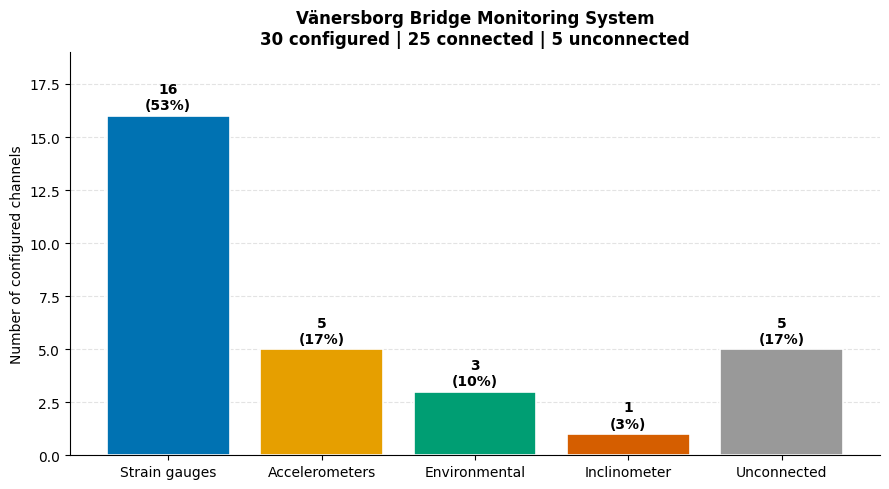

In [ ]:
import matplotlib.pyplot as plt

labels = [
    "Strain gauges",
    "Accelerometers",
    "Environmental",
    "Inclinometer",
    "Unconnected"
]

counts = [16, 5, 3, 1, 5]
colors = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#999999"]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    labels,
    counts,
    color=colors,
    edgecolor="white",
    linewidth=1.2
)

ax.set_title(
    "Vänersborg Bridge Monitoring System\n"
    "30 configured | 25 connected | 5 unconnected",
    fontweight="bold"
)

ax.set_ylabel("Number of configured channels")
ax.set_ylim(0, 19)

for bar, count in zip(bars, counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count + 0.3,
        f"{count}\n({count / 30:.0%})",
        ha="center",
        fontweight="bold"
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Keep only horizontal grid lines
ax.grid(False)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 2. Problem Characterization

### Definition

The aim of this project is to support bridge inspection decisions by developing interpretable event-level indicators of unusual structural behavior from multivariate monitoring data.

The practical objectives are:

1. **Determine whether** bridge-monitoring data can support inspection prioritization by distinguishing unusual structural behavior from normal operational variability.

2. **Assess warning reliability** by comparing multivariate and univariate indicators using post-damage warnings, detection delay, and reference-period sensitivity.

3. **Develop evidence-based guidance** for interpreting anomaly warnings and supporting inspection decisions, while clearly stating the uncertainty and limitations of the analysis.

### Scope
The project focuses on event-level analysis of high-frequency sensor measurements from the Vänersborg Bridge. It **does not** attempt to predict remaining useful life or automatically classify damage. Instead, it evaluates whether interpretable condition indicators can support inspection prioritization.

Because only one verified damage event is available, supervised damage classification would lack sufficient labeled examples. This project therefore uses **unsupervised reference-based anomaly detection** to learn normal pre-damage behavior and identify later deviations.

### Importance

Early identification of unusual structural behavior can support inspection review and maintenance-related assessment, reduce unnecessary inspections, and provide additional evidence for safety-related decisions beyond periodic visual inspection.

### Challenging aspects

- Operational variation between bridge-opening events
- Environmental influence on sensor responses
- Measurement noise and invalid readings
- Correlated and high-dimensional sensor data
- Few confirmed damage events
- Limited monitoring duration





### Problem Formulation

For monitoring event \(e\), the feature vector is

$$
\mathbf{x}_e =
[x_{e,1},x_{e,2},\ldots,x_{e,p}]^{T}.
$$

A condition indicator measures deviation from normal pre-damage behavior:

$$
H_e=f(\mathbf{x}_e).
$$

A warning is generated when the indicator reaches or exceeds the reference-based threshold:

$$
A_e =
\begin{cases}
1, & H_e \geq \tau,\\
0, & H_e < \tau.
\end{cases}
$$

The analysis evaluates reference-period warnings, post-damage warnings, detection delay, and threshold sensitivity.

In the implementation, $\mathbf{x}_e$ is the event-level vector of numerical sensor features. For the primary method, $H_e$ is the PCA–Mahalanobis condition indicator stored in `Condition_indicator`. For the comparative methods, it is the `Baseline_score` or `Directional_score`. The threshold $\tau$ is estimated from the pre-damage reference events for each method, and $A_e$ is represented by the corresponding Boolean `Warning` value. This warning indicates an unusual observation and is not itself a confirmed damage label.





## 3. Related Work

Recent bridge structural-health-monitoring studies have increasingly used data-driven approaches to identify unusual behavior from sensor measurements. Within this broader framework, statistical pattern recognition, principal component analysis (PCA), clustering, Mahalanobis distance, and other unsupervised methods have been applied to extract meaningful patterns, characterize normal structural behavior, and detect potential damage [1]–[5]. These approaches are particularly relevant when confirmed damage observations are limited.

**Strengths.** A major strength of these approaches is their ability to extract useful information from monitoring data without requiring extensive damage labels. Statistical pattern-recognition methods transform sensor measurements into features and compare them with an undamaged reference condition [1]. Building on this reference-based principle, unsupervised methods characterize normal bridge behavior without requiring many labeled damage cases. Within this framework, PCA reduces redundancy and correlation among multisensor features, including features influenced by environmental and operational conditions [3]. Mahalanobis distance complements PCA by providing an interpretable multivariate deviation score while accounting for covariance among features [3], [4]. Clustering can further group observations or feature patterns according to their similarity without requiring predefined damage labels [3]. Beyond methodological developments, the availability of a real bridge dataset containing measurements before, during, and after a verified damage event provides valuable field-based evaluation [2]. Using such data, multiple unsupervised algorithms and feature representations have been applied to comparable bridge-opening events [5].

**Limitations.** Despite these advantages, the reliability of the resulting detection depends on several methodological choices. Detection performance is affected by feature quality, reference-period definition, covariance estimation, and threshold selection. Environmental and operational variability also produce false alarms [4]. Furthermore, PCA is a linear transformation and does not always separate healthy and damaged behavior effectively. Complex hybrid methods reduce interpretability, while a general anomaly score does not identify the responsible sensor or structural direction. Moreover, several studies rely partly on simulated damage, whereas real verified damage events remain limited [2], [3].

**Research gap.** Existing studies demonstrate the potential of unsupervised bridge-damage detection, but limited attention has been given to whether these methods can reliably support inspection prioritization in a real dataset with only one verified damage event. In particular, the combined effects of post-damage warnings, detection delay, and reference-period sensitivity have not been examined through a direct comparison of multivariate and univariate indicators. This project addresses this gap by evaluating these measures and developing interpretable, evidence-based guidance for inspection decisions while stating the analysis limitations.

### References

[1] E. Figueiredo and J. Brownjohn, “Three decades of statistical pattern recognition paradigm for SHM of bridges,” *Structural Health Monitoring*, vol. 21, no. 6, pp. 3018–3054, 2022.

[2] J. Leander, J. Nyman, R. Karoumi, P. Rosengren, and G. Johansson, “Dataset for damage detection retrieved from a monitored bridge pre and post verified damage,” *Data in Brief*, vol. 51, Art. no. 109729, 2023.

[3] A. Meixedo, J. Santos, D. Ribeiro, R. Calçada, and M. D. Todd, “Online unsupervised detection of structural changes using train-induced dynamic responses,” *Mechanical Systems and Signal Processing*, vol. 165, Art. no. 108268, 2022.

[4] H. Sarmadi and A. Karamodin, “A novel anomaly detection method based on adaptive Mahalanobis-squared distance and one-class kNN rule for structural health monitoring under environmental effects,” *Mechanical Systems and Signal Processing*, vol. 140, Art. no. 106495, 2020.

[5] I. Bayane, J. Leander, and R. Karoumi, “An unsupervised machine learning approach for real-time damage detection in bridges,” *Engineering Structures*, vol. 308, Art. no. 117971, 2024.

## 4. Data Collection

The dataset is retrieved directly from the Zenodo public API using Python. The notebook identifies the ZIP archive, downloads it only when it is not already cached, verifies that it is a valid archive, and identifies the monitoring-event CSV files.

This procedure makes the analysis reproducible without requiring manual data upload.

The raw files are preserved. Subsequent processing creates analytical copies by converting measurements to numeric values and replacing identified invalid sentinel values with missing values.

In [ ]:
# ◆ STEP 4 | DATA COLLECTION AND SOURCE VERIFICATION

from pathlib import Path
import zipfile
import requests

# ◇ Local cache
CACHE_DIR = Path("/content/bridge_shm")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# ◇ Public dataset record
API_URL = "https://zenodo.org/api/records/8300495"

# ◇ Retrieve dataset metadata
response = requests.get(
    API_URL,
    timeout=60,
)

response.raise_for_status()

metadata = response.json()

# ◇ Identify the ZIP archive
zip_files = [
    file_info
    for file_info in metadata["files"]
    if file_info["key"].lower().endswith(".zip")
]

if not zip_files:
    raise FileNotFoundError(
        "No ZIP dataset was found in the public record."
    )

file_info = zip_files[0]
zip_name = file_info["key"]
zip_path = CACHE_DIR / zip_name
if zip_path.exists() and not zipfile.is_zipfile(zip_path):
    zip_path.unlink()
    print("✓ Invalid cached archive removed.")

# ◇ Download only if not already cached
if not zip_path.exists():

    download_url = file_info["links"]["self"]

    print(f"Downloading {zip_name} ...")

    with requests.get(
        download_url,
        stream=True,
        timeout=120,
    ) as download:

        download.raise_for_status()

        with open(zip_path, "wb") as output_file:

            for chunk in download.iter_content(
                chunk_size=1024 * 1024
            ):
                if chunk:
                    output_file.write(chunk)

    print("✓ Dataset downloaded.")

else:
    print("✓ Cached dataset found.")

# ◇ Verify archive integrity
if not zipfile.is_zipfile(zip_path):
    raise ValueError(
        "The downloaded file is not a valid ZIP archive."
    )

# ◇ Identify event files
with zipfile.ZipFile(zip_path) as archive:

    csv_names = sorted([
        name
        for name in archive.namelist()
        if name.lower().endswith(".csv")
    ])

if not csv_names:
    raise FileNotFoundError(
        "No monitoring-event CSV files were found."
    )

print("✓ Dataset source verified")
print(f"✓ Archive: {zip_path.name}")
print(f"✓ Monitoring-event files: {len(csv_names)}")

✓ Dataset downloaded.
✓ Dataset source verified
✓ Archive: DiB.zip
✓ Monitoring-event files: 64


## 5. Data Quality and Sensor Configuration

Before feature engineering, the monitoring files are checked for structural consistency and data quality.

The check:

- Counts the monitoring events.
- Verifies the expected sensor channels.
- Converts timestamps to date-time format and checks event duration.
- Checks missing values, duplicate records, and repeated timestamps.
- Detects invalid sentinel values in connected channels.
- Excludes unconnected channels from the quality assessment.
- Preserves event identity and time information.

The validated measurements are then used to construct event-level features for modeling.

In [ ]:
# ◆ STEP 5 | DATA QUALITY AND SENSOR CONFIGURATION

import numpy as np
import pandas as pd
from IPython.display import display

# ◇ Sensor configuration
sensor_channels = [
    f"ch_{i}"
    for i in range(1, 31)
]

unconnected_channels = [
    "ch_17",
    "ch_23",
    "ch_24",
    "ch_26",
    "ch_27",
]

connected_channels = [
    channel
    for channel in sensor_channels
    if channel not in unconnected_channels
]

error_codes = [
    -1_000_000,
    8e15,
]

# ◇ Audit event files
audit_records = []
reference_columns = None

with zipfile.ZipFile(zip_path) as archive:

    for event_number, csv_name in enumerate(csv_names):

        with archive.open(csv_name) as file:
            raw = pd.read_csv(file)

        current_columns = tuple(raw.columns)

        if reference_columns is None:
            reference_columns = current_columns

        missing_channels = [
            channel
            for channel in sensor_channels
            if channel not in raw.columns
        ]

        if missing_channels:
            raise ValueError(
                f"{csv_name} is missing: {missing_channels}"
            )

        timestamps = pd.to_datetime(
            raw["ts"],
            errors="coerce",
        )

        # Audit only the connected channels
        connected_sensor_data = raw[
            connected_channels
        ].apply(
            pd.to_numeric,
            errors="coerce",
        )

        invalid_count = int(
            connected_sensor_data
            .isin(error_codes)
            .sum()
            .sum()
        )

        audit_records.append({
            "Event": event_number,
            "File": csv_name,
            "Rows": len(raw),
            "Columns": raw.shape[1],
            "Missing values": int(
                raw.isna().sum().sum()
            ),
            "Duplicate rows": int(
                raw.duplicated().sum()
            ),
            "Repeated timestamps": int(
                timestamps.duplicated().sum()
            ),
            "Invalid connected-channel values": (
                invalid_count
            ),
            "Duration_seconds": (
                timestamps.max()
                - timestamps.min()
            ).total_seconds(),
            "Column structure matches": (
                current_columns
                == reference_columns
            ),
        })

quality_audit = pd.DataFrame(
    audit_records
)

# ◇ Summary
quality_summary = pd.DataFrame({
    "Indicator": [
        "Monitoring events",
        "Configured channels",
        "Connected channels",
        "Observation rows",
        "Missing values",
        "Duplicate rows",
        "Repeated timestamps",
        "Invalid connected-channel values",
        "Matching file structures",
    ],
    "Result": [
        len(quality_audit),
        len(sensor_channels),
        len(connected_channels),
        f"{quality_audit['Rows'].sum():,}",
        f"{quality_audit['Missing values'].sum():,}",
        f"{quality_audit['Duplicate rows'].sum():,}",
        f"{quality_audit['Repeated timestamps'].sum():,}",
        f"{quality_audit['Invalid connected-channel values'].sum():,}",
        int(
            quality_audit[
                "Column structure matches"
            ].sum()
        ),
    ],
})

display(quality_summary)
display(quality_audit.head())

,Indicator,Result
0,Monitoring events,64
1,Configured channels,30
2,Connected channels,25
3,Observation rows,"9,411,768"
4,Missing values,0
5,Duplicate rows,0
6,Repeated timestamps,"9,364,591"
7,Invalid connected-channel values,"5,945,724"
8,Matching file structures,64


,Event,File,Rows,Columns,Missing values,Duplicate rows,Repeated timestamps,Invalid connected-channel values,Duration_seconds,Column structure matches
0,0,2023_02_20T03_10_53.csv,49834,35,0,0,49583,49834,249.0,True
1,1,2023_02_20T03_17_23.csv,127423,35,0,0,126784,127423,637.0,True
2,2,2023_02_20T19_17_06.csv,108601,35,0,0,108056,108601,543.0,True
3,3,2023_02_20T20_35_06.csv,104806,35,0,0,104280,104806,524.0,True
4,4,2023_02_21T07_54_28.csv,87643,35,0,0,87203,87645,438.0,True


### Interpretation

The dataset contains 64 structurally consistent monitoring-event files with no missing values or duplicate rows. The 5,945,724 invalid connected-channel readings are treated as missing during preprocessing and are not used in feature calculations.

The repeated timestamps are expected because structural sensors and environmental sensors operate at different sampling frequencies. They do not indicate duplicate records.

The audit confirms that the dataset is suitable for feature engineering after applying consistent invalid-value handling.

Invalid sentinel values are treated as data-quality errors and replaced before feature extraction. In contrast, unusual but valid observations are retained because they may represent meaningful structural-condition changes and are evaluated by the anomaly-detection methods.`

### Data-Quality Demonstration

Invalid connected-channel readings are shown by monitoring event. This verifies the scale and distribution of the sensor-quality problem before invalid values are replaced and features are calculated.

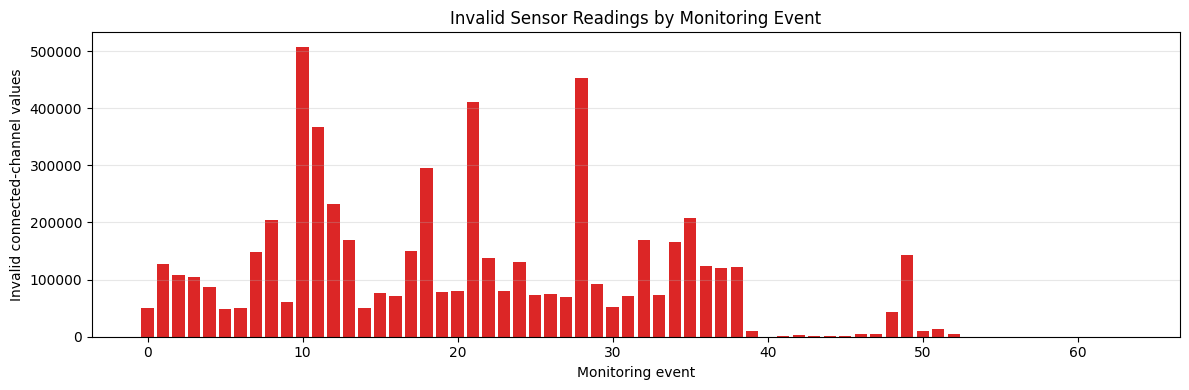

In [ ]:
# ◆ STEP 5 | INVALID-READING DISTRIBUTION

import matplotlib.pyplot as plt

quality_plot = quality_audit.sort_values(
    "Event"
)

plt.figure(
    figsize=(12, 4)
)

plt.bar(
    quality_plot["Event"],
    quality_plot[
        "Invalid connected-channel values"
    ],
    color="#DC2626",
)

plt.xlabel("Monitoring event")
plt.ylabel("Invalid connected-channel values")
plt.title("Invalid Sensor Readings by Monitoring Event")
plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()
plt.show()

### Interpretation

Invalid readings are concentrated in particular monitoring events rather than distributed uniformly. This supports treating them as sensor-quality issues and replacing them consistently before feature extraction.

## 6. Feature Engineering

The raw data contain many sensor readings for each bridge-opening event. Because events contain different numbers of readings, they cannot be compared directly.

The code therefore summarizes each event into one row:

**Raw sensor readings → summary statistics → one event-level feature row**

For each of the 25 connected channels, the code calculates nine statistics: mean, standard deviation, minimum, maximum, range, median, 25th percentile, 75th percentile, and invalid-reading count.

The row also retains five event descriptors: event number, file name, event timestamp, number of raw readings, and event duration.

This creates a 230-column feature repository for the 64 events. The repository is then reduced to four selected statistics—mean, standard deviation, range, and invalid-reading count—for the final anomaly-detection model.

In [ ]:
# ◆ STEP 6 | EVENT-LEVEL FEATURE EXTRACTION

feature_records = []

with zipfile.ZipFile(zip_path) as archive:

    for event_number, csv_name in enumerate(csv_names):

        with archive.open(csv_name) as file:
            raw = pd.read_csv(file)

        # ◇ Convert connected sensor measurements to numeric
        sensor_data = raw[
            connected_channels
        ].apply(
            pd.to_numeric,
            errors="coerce",
        )

        # ◇ Count invalid readings before replacement
        invalid_counts = (
            sensor_data.isin(error_codes)
            .sum()
        )

        # ◇ Replace invalid values with missing values
        clean_data = sensor_data.replace(
            error_codes,
            np.nan,
        )

        # ◇ Convert timestamps
        timestamps = pd.to_datetime(
            raw["ts"],
            errors="coerce",
        )

        event_time = timestamps.iloc[0]

        duration_seconds = (
            timestamps.max()
            - timestamps.min()
        ).total_seconds()

        # ◇ Event-level metadata
        event_features = {
            "Event": event_number,
            "File": csv_name,
            "Time": event_time,
            "Rows": len(raw),
            "Duration_seconds": duration_seconds,
        }

        # ◇ Statistical features for each channel
        for channel in connected_channels:

            values = clean_data[channel].dropna()

            if values.empty:
                statistics = {
                    "mean": np.nan,
                    "std": np.nan,
                    "min": np.nan,
                    "max": np.nan,
                    "range": np.nan,
                    "median": np.nan,
                    "q25": np.nan,
                    "q75": np.nan,
                }

            else:
                statistics = {
                    "mean": values.mean(),
                    "std": values.std(),
                    "min": values.min(),
                    "max": values.max(),
                    "range": (
                        values.max()
                        - values.min()
                    ),
                    "median": values.median(),
                    "q25": values.quantile(0.25),
                    "q75": values.quantile(0.75),
                }

            for name, value in statistics.items():
                event_features[
                    f"{channel}_{name}"
                ] = value

            event_features[
                f"{channel}_invalid"
            ] = int(
                invalid_counts[channel]
            )

        feature_records.append(event_features)

# ◇ Final feature repository
event_features = (
    pd.DataFrame(feature_records)
    .sort_values("Time")
    .reset_index(drop=True)
)

print(
    f"✓ Events processed: "
    f"{len(event_features)}"
)

print(
    f"✓ Feature columns created: "
    f"{event_features.shape[1]}"
)

print(
    f"✓ Connected channels represented: "
    f"{len(connected_channels)}"
)

display(event_features.head())

✓ Events processed: 64
✓ Feature columns created: 230
✓ Connected channels represented: 25


,Event,File,Time,Rows,Duration_seconds,ch_1_mean,ch_1_std,ch_1_min,ch_1_max,ch_1_range,...,ch_29_invalid,ch_30_mean,ch_30_std,ch_30_min,ch_30_max,ch_30_range,ch_30_median,ch_30_q25,ch_30_q75,ch_30_invalid
0,0,2023_02_20T03_10_53.csv,2023-02-20 03:10:53,49834,249.0,458.738049,17.341342,428.55,485.68,57.13,...,0,3.772232,4.478601e-02,3.7,3.8,0.1,3.8,3.7,3.8,0
1,1,2023_02_20T03_17_23.csv,2023-02-20 03:17:23,127423,637.0,443.532535,16.759065,429.48,485.66,56.18,...,0,3.949669,1.058188e-01,3.8,4.1,0.3,4.0,3.9,4.0,0
2,2,2023_02_20T19_17_06.csv,2023-02-20 19:17:06,108601,543.0,454.085655,18.385800,436.87,497.62,60.75,...,0,5.100000,1.031890e-11,5.1,5.1,0.0,5.1,5.1,5.1,0
3,3,2023_02_20T20_35_06.csv,2023-02-20 20:35:06,104806,524.0,454.443560,18.455149,435.28,498.04,62.76,...,0,4.956289,4.960317e-02,4.9,5.0,0.1,5.0,4.9,5.0,0
4,4,2023_02_21T07_54_28.csv,2023-02-21 07:54:28,87643,438.0,453.224339,19.896983,430.54,493.60,63.06,...,0,4.304518,1.063066e-01,4.2,4.5,0.3,4.3,4.2,4.4,0


### Interpretation

The feature repository contains 230 columns: 5 descriptors + (25 channels × 9 statistics) = 230 columns

This complete table preserves information for later analysis. Because only 64 monitoring events are available, a smaller feature set will be selected before anomaly detection to reduce redundancy and overfitting.

### Modeling-Channel Selection

The dataset contains 25 connected channels, but only 64 monitoring events are available. Using all channels could introduce redundant variables and make the feature set unnecessarily large. Therefore, nine channels were selected to retain relevant structural, vibration, inclination, and environmental information while keeping the model interpretable.

The selected channels are:

- `ch_9`, `ch_10`: SG9 and SG10 strain gauges
- `ch_14`, `ch_16`: SG14 and SG16 strain gauges
- `ch_18`: A1 accelerometer
- `ch_25`: inclinometer
- `ch_28`, `ch_29`, `ch_30`: wind direction, wind speed, and air temperature

SG9 and SG10 were included because the dataset article identifies them as close to the documented crack [2]. The selection includes 4 of 16 strain gauges, 1 of 5 accelerometers, the only inclinometer, and all 3 environmental channels. This is a practical engineering-informed selection, not a claim that these nine channels are uniquely optimal.

In [ ]:
# ◆ STEP 6 | ENGINEERING-INFORMED FEATURE SELECTION

# Selected connected channels for modeling
selected_channels = [
    "ch_9",
    "ch_10",
    "ch_14",
    "ch_16",
    "ch_18",
    "ch_25",
    "ch_28",
    "ch_29",
    "ch_30",
]

selected_statistics = [
    "mean",
    "std",
    "range",
    "invalid",
]

# ◇ Preserve event descriptors
reduced_columns = [
    "Event",
    "File",
    "Time",
    "Rows",
    "Duration_seconds",
]

# ◇ Select engineering-relevant features
for channel in selected_channels:

    for statistic in selected_statistics:

        column_name = (
            f"{channel}_{statistic}"
        )

        if column_name in event_features.columns:
            reduced_columns.append(
                column_name
            )

model_features = event_features[
    reduced_columns
].copy()

print(
    f"✓ Complete feature repository: "
    f"{event_features.shape[1]} columns"
)

print(
    f"✓ Reduced modeling table: "
    f"{model_features.shape[1]} columns"
)

display(model_features.head())

✓ Complete feature repository: 230 columns
✓ Reduced modeling table: 41 columns


,Event,File,Time,Rows,Duration_seconds,ch_9_mean,ch_9_std,ch_9_range,ch_9_invalid,ch_10_mean,...,ch_28_range,ch_28_invalid,ch_29_mean,ch_29_std,ch_29_range,ch_29_invalid,ch_30_mean,ch_30_std,ch_30_range,ch_30_invalid
0,0,2023_02_20T03_10_53.csv,2023-02-20 03:10:53,49834,249.0,902.769320,183.184576,513.20,0,782.302235,...,26.0,0,4.784802,0.829626,3.5,0,3.772232,4.478601e-02,0.1,0
1,1,2023_02_20T03_17_23.csv,2023-02-20 03:17:23,127423,637.0,1066.098414,173.510731,516.98,0,877.082953,...,45.0,0,3.795870,0.554062,2.9,0,3.949669,1.058188e-01,0.3,0
2,2,2023_02_20T19_17_06.csv,2023-02-20 19:17:06,108601,543.0,1056.954370,181.864323,529.25,0,874.070635,...,358.0,0,2.889177,1.516782,6.6,0,5.100000,1.031890e-11,0.0,0
3,3,2023_02_20T20_35_06.csv,2023-02-20 20:35:06,104806,524.0,1052.902497,183.563184,527.59,0,870.925330,...,355.0,0,2.731439,1.295416,5.0,0,4.956289,4.960317e-02,0.1,0
4,4,2023_02_21T07_54_28.csv,2023-02-21 07:54:28,87643,438.0,1049.938209,192.196836,544.77,0,883.054539,...,358.0,0,2.126525,1.446647,6.1,0,4.304518,1.063066e-01,0.3,0


### Interpretation

The code reduces the complete 230-column feature repository to a 41-column modeling table using nine of the 25 connected channels.
The reduced modeling table is passed to the next step for standardization and PCA–Mahalanobis analysis.

In [ ]:
# ◆ STEP 6 | FEATURE SCALING AND NORMALIZATION

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# ◇ Keep metadata separate
metadata_columns = [
    "Event",
    "File",
    "Time",
    "Rows",
    "Duration_seconds",
]

feature_columns = [
    column
    for column in model_features.columns
    if column not in metadata_columns
]

X = model_features[feature_columns].copy()

X = X.replace(
    [np.inf, -np.inf],
    np.nan,
)

# ◇ Pre-damage reference events
damage_date = pd.Timestamp("2023-03-09 23:45:25")

reference_mask = (
    model_features["Time"]
    < damage_date
)

# ◇ Fit imputation and scaling only on reference events
imputer = SimpleImputer(
    strategy="median",
)

X_reference_imputed = imputer.fit_transform(
    X.loc[reference_mask]
)

X_all_imputed = imputer.transform(X)

scaler = StandardScaler()

scaler.fit(X_reference_imputed)

X_scaled = scaler.transform(
    X_all_imputed
)

# ◇ Scaled feature table
scaled_features = pd.DataFrame(
    X_scaled,
    columns=feature_columns,
    index=model_features.index,
)

# ◇ Add metadata without scaling
for column in metadata_columns:
    scaled_features[column] = (
        model_features[column].values
    )

scaled_features = scaled_features[
    metadata_columns + feature_columns
]

print(
    f"✓ Features scaled: "
    f"{len(feature_columns)}"
)

print(
    f"✓ Reference events: "
    f"{reference_mask.sum()}"
)

print(
    f"✓ Events transformed: "
    f"{len(scaled_features)}"
)

display(scaled_features.head())

✓ Features scaled: 36
✓ Reference events: 57
✓ Events transformed: 64


,Event,File,Time,Rows,Duration_seconds,ch_9_mean,ch_9_std,ch_9_range,ch_9_invalid,ch_10_mean,...,ch_28_range,ch_28_invalid,ch_29_mean,ch_29_std,ch_29_range,ch_29_invalid,ch_30_mean,ch_30_std,ch_30_range,ch_30_invalid
0,0,2023_02_20T03_10_53.csv,2023-02-20 03:10:53,49834,249.0,-2.179205,0.376673,-1.927019,0.0,-2.194013,...,-1.959501,0.0,3.172386,0.631875,0.497927,0.0,0.751571,-0.431083,-0.524275,0.0
1,1,2023_02_20T03_17_23.csv,2023-02-20 03:17:23,127423,637.0,0.286885,0.035645,-1.590417,0.0,0.169941,...,-1.815265,0.0,2.242817,-0.047159,0.175406,0.0,0.807431,0.334908,0.262138,0.0
2,2,2023_02_20T19_17_06.csv,2023-02-20 19:17:06,108601,543.0,0.148820,0.330131,-0.497795,0.0,0.094810,...,0.560828,0.0,1.390550,2.325138,2.164284,0.0,1.169569,-0.993168,-0.917481,0.0
3,3,2023_02_20T20_35_06.csv,2023-02-20 20:35:06,104806,524.0,0.087641,0.390020,-0.645615,0.0,0.016362,...,0.538054,0.0,1.242281,1.779657,1.304228,0.0,1.124327,-0.370625,-0.524275,0.0
4,4,2023_02_21T07_54_28.csv,2023-02-21 07:54:28,87643,438.0,0.042884,0.694379,0.884233,0.0,0.318880,...,0.560828,0.0,0.673678,2.152313,1.895516,0.0,0.919142,0.341031,0.262138,0.0


### Interpretation

The 36 numerical modeling features (9 selected channels × 4 statistics = 36 features, excluding the five event descriptors) were standardized using only the 57 pre-damage events. The same imputation and scaling parameters were then applied to all 64 events, while event metadata were kept unchanged.

Median imputation was used because it is less sensitive to extreme values, and the imputation statistic was fitted only on pre-damage reference events to avoid using post-damage information.

Negative standardized values indicate measurements below the reference mean; they do not represent negative physical quantities.

The scaled features are now suitable for PCA and multivariate anomaly detection.



### Feature-Correlation Demonstration

The correlation matrix shows relationships among the standardized modeling features. Strong correlations indicate redundancy and support using PCA to obtain a compact multisensor representation.

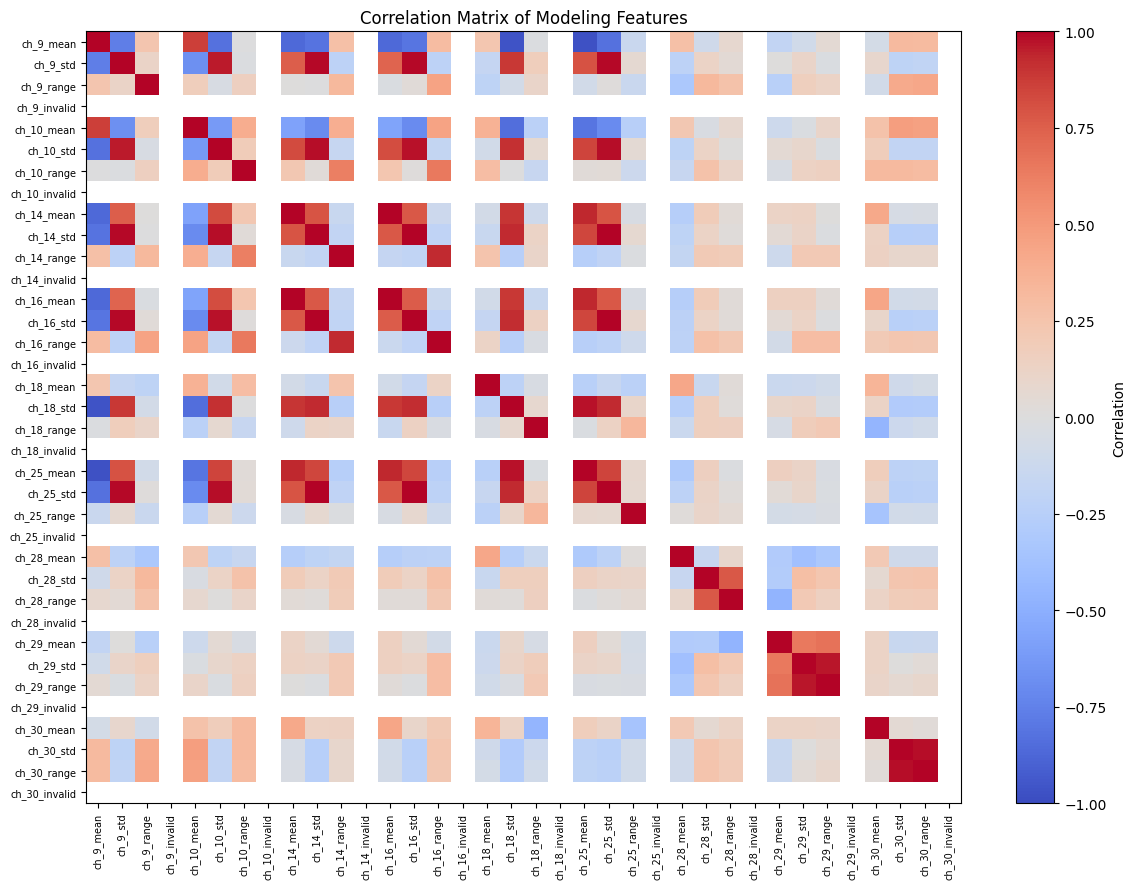

In [ ]:
# ◆ STEP 6 | FEATURE-CORRELATION HEATMAP

import matplotlib.pyplot as plt

correlation_matrix = scaled_features[
    feature_columns
].corr()

plt.figure(
    figsize=(12, 9)
)

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto",
)

plt.colorbar(
    label="Correlation"
)

plt.xticks(
    range(len(feature_columns)),
    feature_columns,
    rotation=90,
    fontsize=7,
)

plt.yticks(
    range(len(feature_columns)),
    feature_columns,
    fontsize=7,
)

plt.title(
    "Correlation Matrix of Modeling Features"
)

plt.tight_layout()
plt.show()

### Interpretation

The heatmap shows redundancy among the modeling features. Within several channels, the mean, standard deviation, and range are positively related. Some cross-channel relationships are also visible among CH14, CH16, and CH25, which may reflect related bridge responses.

The environmental channels CH28–CH30 show different correlation patterns and provide operating-condition information rather than duplicating the strain features. Negative correlations indicate features that tend to move in opposite directions in some events.

PCA is useful here because it combines correlated features into fewer uncorrelated components while retaining most of the reference-period variation. This creates a more compact input for the Mahalanobis-distance calculation.

These correlations show statistical association, not causation. They do not establish that one sensor or operating condition caused another response.

**PCA (Principal Component Analysis) is a dimensionality-reduction method. It combines correlated standardized features into a smaller number of uncorrelated components while retaining most of the information in the original features.**

In [ ]:
# ◆ STEP 6 | DIMENSIONALITY REDUCTION AND SENSOR FUSION

from sklearn.decomposition import PCA

# ◇ Extract scaled numerical features
X_scaled = scaled_features[
    feature_columns
].to_numpy()

X_reference_scaled = X_scaled[
    reference_mask.to_numpy()
]

# ◇ Fit PCA using only pre-damage reference events
pca_full = PCA()

pca_full.fit(
    X_reference_scaled
)

# ◇ Select components explaining at least 95% variance
cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

n_components = int(
    np.argmax(
        cumulative_variance >= 0.95
    ) + 1
)

pca = PCA(
    n_components=n_components
)

pca.fit(
    X_reference_scaled
)

# ◇ Transform all monitoring events
principal_components = pca.transform(
    X_scaled
)

pca_scores = pd.DataFrame(
    principal_components,
    columns=[
        f"PC{i + 1}"
        for i in range(n_components)
    ],
)

pca_scores.insert(
    0,
    "Time",
    model_features["Time"].values,
)

pca_scores.insert(
    0,
    "Event",
    model_features["Event"].values,
)

print(
    f"✓ Original numerical features: "
    f"{len(feature_columns)}"
)

print(
    f"✓ PCA components retained: "
    f"{n_components}"
)

print(
    f"✓ Cumulative explained variance: "
    f"{cumulative_variance[n_components - 1]:.3f}"
)

display(pca_scores.head())

✓ Original numerical features: 36
✓ PCA components retained: 10
✓ Cumulative explained variance: 0.958


,Event,Time,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,0,2023-02-20 03:10:53,4.885713,-4.445057,3.230650,-3.553629,-0.742007,1.172274,-0.209309,0.779205,0.816725,0.509072
1,1,2023-02-20 03:17:23,0.196731,-4.087287,2.180737,-2.505696,-2.015765,1.038511,1.322471,-0.200982,-0.985578,-0.633343
2,2,2023-02-20 19:17:06,0.375644,0.051416,2.970490,-0.037397,2.228214,0.910494,0.274531,0.195493,-1.821623,-0.604308
3,3,2023-02-20 20:35:06,0.263694,0.215101,1.828724,-0.322887,2.555739,0.806882,0.726355,0.409988,-1.069708,-0.453597
4,4,2023-02-21 07:54:28,1.258484,3.921748,2.646065,0.942302,0.123712,-0.119452,-0.741895,-0.210488,-1.427046,-1.707088


### Interpretation

The code retained 10 principal components, PC1–PC10, because they explain 95.7% of the variation in the pre-damage reference events. PCA fitted using 57 events and then used to transform all 64 events.

These are not original sensor features; each is a weighted combination of the 36 standardized features. The loading matrix shows which original features contribute to each component.



These components provide a compact multisensor representation for the subsequent Mahalanobis-distance calculation.

### PCA Explained Variance

The explained-variance plot shows how much reference-period variation is captured by each principal component and cumulatively by the retained components. It supports the selection of the number of components used in the anomaly-detection model.

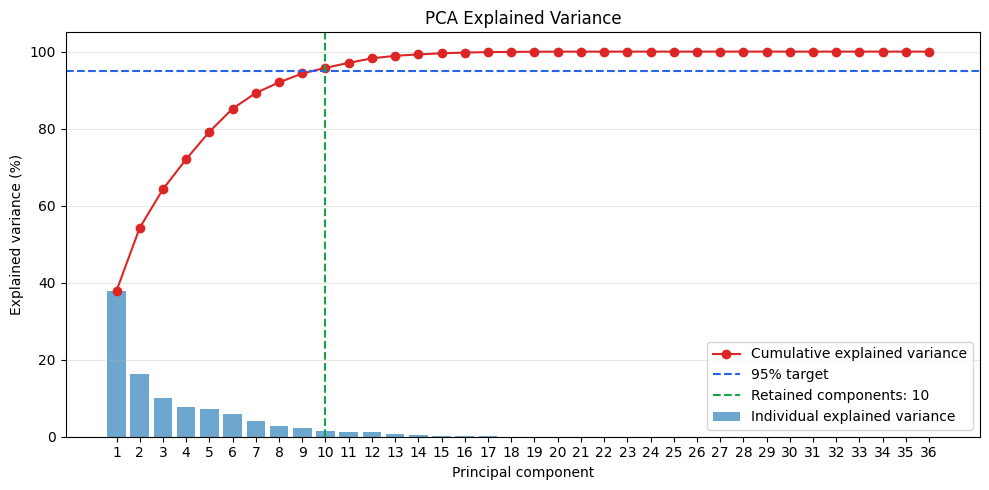

In [ ]:
# ◆ STEP 6 | PCA EXPLAINED-VARIANCE PLOT

import matplotlib.pyplot as plt

component_numbers = np.arange(
    1,
    len(pca_full.explained_variance_ratio_) + 1,
)

individual_variance = (
    pca_full.explained_variance_ratio_
    * 100
)

cumulative_variance = (
    np.cumsum(
        pca_full.explained_variance_ratio_
    )
    * 100
)

fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.bar(
    component_numbers,
    individual_variance,
    alpha=0.65,
    label="Individual explained variance",
)

ax.plot(
    component_numbers,
    cumulative_variance,
    marker="o",
    color="#DC2626",
    label="Cumulative explained variance",
)

ax.axhline(
    95,
    color="#2563EB",
    linestyle="--",
    label="95% target",
)

ax.axvline(
    n_components,
    color="#16A34A",
    linestyle="--",
    label=f"Retained components: {n_components}",
)

ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance (%)")
ax.set_title("PCA Explained Variance")
ax.set_xticks(component_numbers)
ax.grid(
    axis="y",
    alpha=0.3,
)

ax.legend()
plt.tight_layout()
plt.show()

### Interpretation

The plot shows the variance captured by each principal component and the cumulative variance retained by the selected components. The vertical line identifies the number of components used in the anomaly-detection model, while the horizontal line marks the 95% variance target.

In [ ]:
# ◆ PCA LOADINGS | Relationship between original features and PCs

loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_columns,
    columns=[
        f"PC{i + 1}"
        for i in range(n_components)
    ],
)

display(loadings.round(2).head(10))

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
ch_9_mean,-0.30,0.05,-0.04,-0.02,0.04,0.00,0.16,-0.07,-0.19,0.04
ch_9_std,0.29,0.07,-0.07,0.02,0.04,-0.05,0.21,-0.08,-0.22,0.01
ch_9_range,-0.01,0.41,-0.08,-0.08,-0.08,-0.21,0.01,-0.06,-0.10,0.37
ch_9_invalid,-0.00,-0.00,0.00,0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00
ch_10_mean,-0.27,0.14,-0.05,-0.13,0.05,0.02,0.18,-0.01,-0.12,0.07
ch_10_std,0.29,0.07,-0.07,0.01,0.03,-0.05,0.20,-0.07,-0.18,0.03
ch_10_range,-0.06,0.39,-0.09,0.06,0.07,-0.24,0.07,0.04,0.10,0.35
ch_10_invalid,-0.00,-0.00,0.00,-0.00,0.00,0.00,0.00,0.00,-0.00,0.00
ch_14_mean,0.27,0.12,-0.02,-0.18,0.03,0.04,-0.07,0.18,0.28,0.01
ch_14_std,0.30,0.06,-0.05,0.03,0.06,-0.05,0.17,-0.07,-0.22,-0.06


### Interpretation

The loading matrix shows the contribution of each original feature to each principal component. Large positive or negative loadings indicate features that contribute strongly to a component. The matrix is used for interpretation; the principal-component scores are used for the Mahalanobis anomaly calculation.

## 7. Primary Method: PCA–Mahalanobis Anomaly Detection

PCA–Mahalanobis anomaly detection is selected because the dataset contains correlated multisensor features and only one verified damage event. PCA reduces feature redundancy and provides a compact representation. Mahalanobis distance then measures each event’s deviation from normal pre-damage behavior while accounting for relationships among variables.

The method is unsupervised and reference-based: it learns normal pre-damage behavior without using event-level damage labels. However, the feature selection is engineering- and dataset-informed, including SG9 and SG10, which are identified in the published dataset description as being close to the documented crack [2].

This approach **addresses the identified literature gap** by testing how feature representation and reference-based thresholding affect warning reliability on a real bridge dataset with one verified damage event.

To assess robustness, the analysis **compares configurations** with different threshold percentiles, reference-period lengths, and selected feature groups. The workflow is **implemented in Python** using NumPy, pandas, Matplotlib, and scikit-learn.

For each event, the ten PCA scores are combined into one Mahalanobis anomaly score:

$$
D_e =
\sqrt{
(\mathbf{z}_e-\boldsymbol{\mu})^T
\boldsymbol{\Sigma}^{-1}
(\mathbf{z}_e-\boldsymbol{\mu})
}
$$

Here, $\mathbf{z}_e$ is the event’s vector of PCA scores, while $\boldsymbol{\mu}$ and $\boldsymbol{\Sigma}$ are calculated from the pre-damage reference events.

The score measures how far the event is from normal pre-damage behavior while accounting for relationships among the PCA components. A warning is generated when the score reaches or exceeds the 99th-percentile reference threshold.

The score measures how far an event is from normal pre-damage behavior while accounting for relationships among the PCA components. In the code, this score is stored as `Condition_indicator`, and a warning is recorded as `Warning` when the score reaches or exceeds the 99th-percentile reference threshold.

In [ ]:
# ◆ STEP 7 | MULTIVARIATE CONDITION INDICATOR

# ◇ PCA scores
Z = pca_scores[
    [f"PC{i + 1}" for i in range(n_components)]
].to_numpy()

Z_reference = Z[
    reference_mask.to_numpy()
]

# ◇ Reference mean and covariance
reference_mean = Z_reference.mean(axis=0)
reference_covariance = np.cov(
    Z_reference,
    rowvar=False,
)

inverse_covariance = np.linalg.pinv(
    reference_covariance
)

# ◇ Mahalanobis anomaly score
condition_scores = []

for row in Z:

    difference = row - reference_mean

    score = np.sqrt(
        difference
        @ inverse_covariance
        @ difference.T
    )

    condition_scores.append(score)

condition_scores = np.asarray(
    condition_scores
)

# ◇ Warning threshold based on normal reference events
warning_threshold = np.percentile(
    condition_scores[
        reference_mask.to_numpy()
    ],
    99,
)

condition_results = pd.DataFrame({
    "Event": model_features["Event"],
    "Time": model_features["Time"],
    "Condition_indicator": condition_scores,
})

condition_results["Warning"] = (
    condition_results["Condition_indicator"]
    >= warning_threshold
)

print(
    f"✓ Warning threshold: "
    f"{warning_threshold:.3f}"
)

print(
    f"✓ Warnings generated: "
    f"{condition_results['Warning'].sum()}"
)

display(condition_results)

✓ Warning threshold: 5.896
✓ Warnings generated: 1


,Event,Time,Condition_indicator,Warning
0,0,2023-02-20 03:10:53,4.474752,False
1,1,2023-02-20 03:17:23,3.906569,False
2,2,2023-02-20 19:17:06,3.536151,False
3,3,2023-02-20 20:35:06,2.832640,False
4,4,2023-02-21 07:54:28,4.201190,False
...,...,...,...,...
59,59,2023-03-10 17:37:28,3.136449,False
60,60,2023-03-10 20:51:26,3.024554,False
61,61,2023-03-11 16:36:25,3.247330,False
62,62,2023-03-11 17:53:02,2.346462,False


### Interpretation

The warning threshold is 5.896, calculated as the 99th percentile of the Mahalanobis scores from the 57 pre-damage reference events. One of the 64 events has a score at or above this threshold and is therefore flagged as a warning. Its timing is examined later to determine whether it occurred before or after the documented damage date.

In [ ]:
# ◆ WARNING REVIEW | Identify flagged events

flagged_events = condition_results[
    condition_results["Warning"]
].copy()

flagged_events["Period"] = np.where(
    flagged_events["Time"] < damage_date,
    "Pre-damage",
    "Post-damage",
)

display(flagged_events)

display(flagged_events)

print(
    f"✓ Flagged events: "
    f"{len(flagged_events)}"
)

,Event,Time,Condition_indicator,Warning,Period
47,47,2023-03-05 05:52:22,7.277896,True,Pre-damage


,Event,Time,Condition_indicator,Warning,Period
47,47,2023-03-05 05:52:22,7.277896,True,Pre-damage


✓ Flagged events: 1


### Interpretation

The model flagged one event: Event 47 on 5 March 2023. Its condition score was 7.278, exceeding the threshold of 5.896. Because this event occurred before the documented damage date, it is classified as a pre-damage warning rather than a post-damage warning.

## 8. Comparative Methods

The PCA–Mahalanobis method is treated as the primary approach because it performs multivariate sensor fusion without using event-level damage labels. The following two methods provide comparisons: a simpler univariate baseline and an exploratory SG9–SG10 directional diagnostic informed by the documented damage pattern.

### 8.1 Secondary Method: Univariate Standardized-Feature Baseline

A univariate standardized-feature baseline is implemented as the secondary approach for comparison with the primary PCA–Mahalanobis method.

For each event, the baseline is defined as the largest absolute standardized feature value:

$$
B_e = \max_j |z_{e,j}|
$$

A warning is generated when $B_e$ exceeds the 99th percentile of the pre-damage reference events.

The baseline is easier to interpret but does not explicitly model correlations between sensors. Comparing it with the PCA–Mahalanobis indicator evaluates the value of multivariate sensor fusion.

In [ ]:
# ◆ STEP 8 | UNIVARIATE BASELINE

# ◇ Use the largest absolute standardized feature
baseline_scores = np.max(
    np.abs(
        scaled_features[feature_columns]
        .to_numpy()
    ),
    axis=1,
)

baseline_threshold = np.percentile(
    baseline_scores[
        reference_mask.to_numpy()
    ],
    99,
)

baseline_results = pd.DataFrame({
    "Event": model_features["Event"],
    "Time": model_features["Time"],
    "Baseline_score": baseline_scores,
})

baseline_results["Warning"] = (
    baseline_results["Baseline_score"]
    >= baseline_threshold
)

print(
    f"✓ Baseline threshold: "
    f"{baseline_threshold:.3f}"
)

print(
    f"✓ Baseline warnings: "
    f"{baseline_results['Warning'].sum()}"
)

display(baseline_results)

✓ Baseline threshold: 5.433
✓ Baseline warnings: 1


,Event,Time,Baseline_score,Warning
0,0,2023-02-20 03:10:53,3.202922,False
1,1,2023-02-20 03:17:23,2.938527,False
2,2,2023-02-20 19:17:06,2.325138,False
3,3,2023-02-20 20:35:06,1.779657,False
4,4,2023-02-21 07:54:28,2.360601,False
...,...,...,...,...
59,59,2023-03-10 17:37:28,2.712028,False
60,60,2023-03-10 20:51:26,2.674105,False
61,61,2023-03-11 16:36:25,3.734142,False
62,62,2023-03-11 17:53:02,3.270037,False


### 8.2 Third Method: SG9–SG10 Directional Diagnostic
This exploratory diagnostic uses the standardized range changes of SG9 and SG10. It checks whether SG9 increases while SG10 decreases after the documented damage event.

Because this direction was selected using knowledge of the documented damage event, the diagnostic is label-informed and is not treated as unbiased predictive evidence.

In [ ]:
# ◆ STEP 8.2 | DIRECTIONAL DAMAGE-CHANGE SCORE

directional_features = [
    "ch_9_range",
    "ch_10_range",
]

X_directional = model_features[
    directional_features
].copy()

# ◇ Reference statistics
reference_mean = (
    X_directional.loc[reference_mask]
    .mean()
)

reference_std = (
    X_directional.loc[reference_mask]
    .std()
)

# ◇ Standardized feature changes
Z_directional = (
    X_directional
    - reference_mean
) / reference_std

# ◇ SG9 increases; SG10 decreases
directional_scores = (
    Z_directional["ch_9_range"]
    - Z_directional["ch_10_range"]
)

directional_threshold = np.percentile(
    directional_scores[
        reference_mask
    ],
    99,
)

directional_results = pd.DataFrame({
    "Event": model_features["Event"],
    "Time": model_features["Time"],
    "Directional_score": directional_scores,
})

directional_results["Warning"] = (
    directional_results["Directional_score"]
    >= directional_threshold
)

print(
    f"✓ Directional threshold: "
    f"{directional_threshold:.3f}"
)

print(
    f"✓ Warnings generated: "
    f"{directional_results['Warning'].sum()}"
)

display(directional_results)

✓ Directional threshold: 1.387
✓ Warnings generated: 8


,Event,Time,Directional_score,Warning
0,0,2023-02-20 03:10:53,0.330607,False
1,1,2023-02-20 03:17:23,0.591751,False
2,2,2023-02-20 19:17:06,0.188198,False
3,3,2023-02-20 20:35:06,0.073899,False
4,4,2023-02-21 07:54:28,0.607590,False
...,...,...,...,...
59,59,2023-03-10 17:37:28,5.007686,True
60,60,2023-03-10 20:51:26,4.602921,True
61,61,2023-03-11 16:36:25,4.924560,True
62,62,2023-03-11 17:53:02,5.019722,True


In [ ]:
# ◆ STEP 8.2 | REVIEW DIRECTIONAL WARNINGS

directional_warnings = directional_results[
    directional_results["Warning"]
].copy()

display(directional_warnings)

,Event,Time,Directional_score,Warning
29,29,2023-03-01 08:13:28,1.412376,True
57,57,2023-03-09 23:45:25,4.173119,True
58,58,2023-03-10 08:34:30,4.801660,True
59,59,2023-03-10 17:37:28,5.007686,True
60,60,2023-03-10 20:51:26,4.602921,True
61,61,2023-03-11 16:36:25,4.924560,True
62,62,2023-03-11 17:53:02,5.019722,True
63,63,2023-03-11 18:34:51,5.575563,True


In [ ]:
# ◆ 8.2 | DIRECTIONAL-METHOD EVALUATION

damage_date = pd.Timestamp(
    "2023-03-09 23:45:25"
)

event_times = pd.to_datetime(
    directional_results["Time"]
)

pre_damage_mask = (
    event_times < damage_date
)

damage_event_mask = (
    event_times == damage_date
)

post_damage_mask = (
    event_times > damage_date
)

directional_reference_warnings = (
    directional_results.loc[
        pre_damage_mask,
        "Warning"
    ].sum()
)

directional_damage_event_warnings = (
    directional_results.loc[
        damage_event_mask,
        "Warning"
    ].sum()
)

directional_post_warnings = (
    directional_results.loc[
        post_damage_mask,
        "Warning"
    ].sum()
)

first_directional_post_warning = (
    directional_results.loc[
        post_damage_mask
        & directional_results["Warning"],
        "Time"
    ].min()
)

if pd.notna(first_directional_post_warning):
    detection_delay = (
        pd.Timestamp(first_directional_post_warning)
        - damage_date
    ).total_seconds() / 86400
else:
    detection_delay = np.nan

directional_summary = pd.DataFrame({
    "Metric": [
        "Pre-damage warnings",
        "Damage-time warnings",
        "Post-damage warnings",
        "First post-damage warning",
        "Detection delay (days)",
    ],
    "Result": [
        int(directional_reference_warnings),
        int(directional_damage_event_warnings),
        int(directional_post_warnings),
        first_directional_post_warning,
        round(detection_delay, 3),
    ],
})

display(directional_summary)

,Metric,Result
0,Pre-damage warnings,1
1,Damage-time warnings,1
2,Post-damage warnings,6
3,First post-damage warning,2023-03-10 08:34:30
4,Detection delay (days),0.367


### Interpretation

The directional diagnostic generated one pre-damage warning, one warning at the documented damage timestamp, and six additional post-damage warnings. The first true **post-damage warning** occurred on 10 March 2023 at 08:34:30, approximately 0.37 days after the documented damage event.

Because the direction was selected using knowledge of the documented damage event, these results are exploratory and label-informed rather than unbiased predictive evidence.

## 9. Evaluation and Results

The three methods are evaluated using the same event-level warning framework. The comparison considers reference-period warnings, held-out pre-damage warnings, post-damage warnings, detection delay, threshold sensitivity, reference-period sensitivity, and engineering interpretation.

### Evaluation metrics and results

**Quantitative measures**

- Reference-period warning count
- Held-out pre-damage warning count
- Post-damage warning count
- Detection delay
- Warning changes across threshold percentiles

The experiments vary the threshold percentile, reference-period length, and selected feature group to assess warning reliability and robustness.

**Qualitative measures**

- Engineering interpretability: whether an engineer can identify and explain the warning contributors.
- Usefulness of warning patterns for inspection review.
- Whether the method distinguishes abnormal behavior from confirmed damage.

Conventional accuracy, precision, and recall are not emphasized because only one verified damage event is available.





In [ ]:
# ◆ WARNING AGREEMENT

pca_warning_events = set(
    condition_results.loc[
        condition_results["Warning"],
        "Event",
    ]
)

baseline_warning_events = set(
    baseline_results.loc[
        baseline_results["Warning"],
        "Event",
    ]
)

print(
    "PCA warning events:",
    sorted(pca_warning_events),
)

print(
    "Baseline warning events:",
    sorted(baseline_warning_events),
)

print(
    "Agreement:",
    pca_warning_events
    == baseline_warning_events,
)

PCA warning events: [47]
Baseline warning events: [47]
Agreement: True


### Interpretation

The PCA–Mahalanobis and univariate baseline methods flagged the same event(s) under the selected threshold. This shows whether the multivariate method produces different warnings from the simpler single-feature rule.

In [ ]:
# ◆ STEP 9 | FEATURE-LEVEL REVIEW OF THE FLAGGED EVENT

warning_event = 47

warning_index = model_features.index[
    model_features["Event"]
    == warning_event
][0]

warning_features = (
    scaled_features.loc[
        warning_index,
        feature_columns,
    ]
    .abs()
    .sort_values(
        ascending=False
    )
)

warning_contributors = pd.DataFrame({
    "Feature": warning_features.index,
    "Absolute standardized value": (
        warning_features.values
    ),
})

display(
    warning_contributors.head(10)
)

,Feature,Absolute standardized value
0,ch_25_range,7.347371
1,ch_18_range,1.916296
2,ch_10_mean,1.699012
3,ch_18_mean,1.695509
4,ch_30_mean,1.651138
5,ch_9_mean,1.324761
6,ch_18_std,1.10458
7,ch_28_std,1.055997
8,ch_25_mean,1.050165
9,ch_9_range,0.944817


### Interpretation

The flagged event is examined at the original-feature level by ranking the absolute standardized values. The feature with the largest value was the inclination range, with an absolute standardized value of approximately 7.24.

These feature values help explain why the event was unusual, but they do not individually determine the PCA–Mahalanobis score or prove structural damage.

In [ ]:
# ◆ STEP 9 | INVALID-FEATURE SENSITIVITY ANALYSIS

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

damage_date = pd.Timestamp(
    "2023-03-09 23:45:25"
)

pre_damage_mask = (
    model_features["Time"]
    < damage_date
).to_numpy()

damage_event_mask = (
    model_features["Time"]
    == damage_date
).to_numpy()

post_damage_mask = (
    model_features["Time"]
    > damage_date
).to_numpy()

# Exclude sensor-quality features
physical_feature_columns = [
    column
    for column in feature_columns
    if not column.endswith("_invalid")
]

X_physical_raw = (
    model_features[
        physical_feature_columns
    ]
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
)

# Fit imputation only on pre-damage events
physical_imputer = SimpleImputer(
    strategy="median"
)

X_physical_reference = (
    physical_imputer.fit_transform(
        X_physical_raw.loc[pre_damage_mask]
    )
)

X_physical_all = (
    physical_imputer.transform(
        X_physical_raw
    )
)

# Fit scaling only on pre-damage events
physical_scaler = StandardScaler()

X_physical_reference = (
    physical_scaler.fit_transform(
        X_physical_reference
    )
)

X_physical_all = (
    physical_scaler.transform(
        X_physical_all
    )
)

# Fit PCA only on pre-damage events
physical_pca_full = PCA().fit(
    X_physical_reference
)

physical_cumulative_variance = np.cumsum(
    physical_pca_full.explained_variance_ratio_
)

physical_n_components = int(
    np.argmax(
        physical_cumulative_variance >= 0.95
    ) + 1
)

physical_pca = PCA(
    n_components=physical_n_components
)

Z_physical_reference = (
    physical_pca.fit_transform(
        X_physical_reference
    )
)

Z_physical_all = (
    physical_pca.transform(
        X_physical_all
    )
)

# Reference mean and covariance
physical_reference_mean = (
    Z_physical_reference.mean(axis=0)
)

physical_inverse_covariance = np.linalg.pinv(
    np.cov(
        Z_physical_reference,
        rowvar=False
    )
)

# Mahalanobis scores
physical_scores = np.array([
    np.sqrt(
        (z - physical_reference_mean)
        @ physical_inverse_covariance
        @ (z - physical_reference_mean).T
    )
    for z in Z_physical_all
])

physical_threshold = np.percentile(
    physical_scores[pre_damage_mask],
    99
)

physical_warnings = (
    physical_scores >= physical_threshold
)

invalid_sensitivity_summary = pd.DataFrame({
    "Metric": [
        "Numerical features",
        "Components retained",
        "Cumulative explained variance",
        "Warning threshold",
        "Pre-damage warnings",
        "Damage-time warnings",
        "Post-damage warnings",
    ],
    "Result": [
        len(physical_feature_columns),
        physical_n_components,
        physical_cumulative_variance[
            physical_n_components - 1
        ],
        physical_threshold,
        int(
            physical_warnings[
                pre_damage_mask
            ].sum()
        ),
        int(
            physical_warnings[
                damage_event_mask
            ].sum()
        ),
        int(
            physical_warnings[
                post_damage_mask
            ].sum()
        ),
    ],
})

display(
    invalid_sensitivity_summary.round(3)
)

,Metric,Result
0,Numerical features,27.000
1,Components retained,10.000
2,Cumulative explained variance,0.958
3,Warning threshold,5.896
4,Pre-damage warnings,1.000
5,Damage-time warnings,0.000
6,Post-damage warnings,0.000


### Interpretation

Removing the nine invalid-reading features reduced the numerical feature count from 36 to 27, but retained 10 principal components and 95.8% of the reference-period variation. The warning threshold remained 5.896, and the warning outcome was unchanged: one pre-damage warning, no damage-time warning, and no post-damage warnings.

This sensitivity check indicates that the primary warning conclusion is not driven by the invalid-reading counts. The original model is therefore retained, while the invalid-reading features are interpreted as supplementary sensor-quality information.

### Threshold Sensitivity Analysis

The warning threshold can affect the number of reference-period warnings and post-damage warnings. To examine this effect, the PCA–Mahalanobis method and the univariate baseline are evaluated using the 95th, 97.5th, and 99th percentiles of their pre-damage reference scores. The 99th-percentile threshold is retained as the primary configuration because it is a conservative screening rule. However, the reference-period warning count is an in-sample empirical result rather than an independent false-alarm estimate, because the threshold is calculated from the same reference observations.

In [ ]:
# ◆ STEP 9 | THRESHOLD SENSITIVITY ANALYSIS

damage_date = pd.Timestamp(
    "2023-03-09 23:45:25"
)

event_times = pd.to_datetime(
    model_features["Time"]
)

reference_mask_sensitivity = (
    event_times < damage_date
)

post_damage_mask_sensitivity = (
    event_times > damage_date
)

threshold_percentiles = [
    95,
    97.5,
    99,
]

sensitivity_records = []

method_scores = {
    "PCA–Mahalanobis": (
        condition_results[
            "Condition_indicator"
        ].to_numpy()
    ),
    "Univariate baseline": (
        baseline_results[
            "Baseline_score"
        ].to_numpy()
    ),
}

for percentile in threshold_percentiles:

    for method_name, scores in method_scores.items():

        reference_scores = scores[
            reference_mask_sensitivity.to_numpy()
        ]

        threshold = np.percentile(
            reference_scores,
            percentile
        )

        warnings = (
            scores >= threshold
        )

        reference_warning_count = int(
            warnings[
                reference_mask_sensitivity.to_numpy()
            ].sum()
        )

        post_damage_warning_count = int(
            warnings[
                post_damage_mask_sensitivity.to_numpy()
            ].sum()
        )

        sensitivity_records.append({
            "Method": method_name,
            "Percentile": percentile,
            "Threshold": threshold,
            "Reference warnings": (
                reference_warning_count
            ),
            "Post-damage warnings": (
                post_damage_warning_count
            ),
        })

threshold_sensitivity = pd.DataFrame(
    sensitivity_records
)

display(
    threshold_sensitivity.round(3)
)

,Method,Percentile,Threshold,Reference warnings,Post-damage warnings
0,PCA–Mahalanobis,95.0,4.256,3,0
1,Univariate baseline,95.0,3.267,3,4
2,PCA–Mahalanobis,97.5,4.676,2,0
3,Univariate baseline,97.5,3.767,2,1
4,PCA–Mahalanobis,99.0,5.896,1,0
5,Univariate baseline,99.0,5.433,1,0


### Interpretation

At the 95th percentile, PCA–Mahalanobis generated 3 reference-period warnings and no post-damage warnings, while the univariate baseline generated 3 reference-period warnings and 4 post-damage warnings.

At the 97.5th percentile, PCA–Mahalanobis generated 2 reference-period warnings and no post-damage warnings, while the baseline generated 2 reference-period warnings and 1 post-damage warning.

At the 99th percentile, both methods generated 1 reference-period warning and no post-damage warnings. The 99th-percentile threshold is retained as the primary setting because it provides the most conservative warning rule.

### Reference-Period Sensitivity Analysis
The primary model uses all 57 pre-damage events as the reference population. To assess robustness, the PCA–Mahalanobis procedure is repeated using the first 70%, 85%, and 100% of the chronological pre-damage events, respectively. For each reference period, imputation, scaling, PCA, covariance estimation, and the warning threshold are fitted using only that period.


In [ ]:
# ◆ STEP 9 | REFERENCE-PERIOD SENSITIVITY

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

damage_date = pd.Timestamp(
    "2023-03-09 23:45:25"
)

X_raw = model_features[
    feature_columns
].replace(
    [np.inf, -np.inf],
    np.nan
)

reference_indices = (
    model_features.loc[
        model_features["Time"] < damage_date
    ]
    .sort_values("Time")
    .index
)

post_damage_mask = (
    model_features["Time"] > damage_date
).to_numpy()

records = []

for fraction in [0.70, 0.85, 1.00]:

    selected_indices = reference_indices[
        :int(len(reference_indices) * fraction)
    ]

    selected_mask = model_features.index.isin(
        selected_indices
    )

    imputer = SimpleImputer(
        strategy="median"
    )

    X_ref_imputed = imputer.fit_transform(
        X_raw.loc[selected_mask]
    )

    X_all_imputed = imputer.transform(
        X_raw
    )

    scaler = StandardScaler()

    X_ref = scaler.fit_transform(
        X_ref_imputed
    )

    X_all = scaler.transform(
        X_all_imputed
    )

    pca_full = PCA().fit(X_ref)

    cumulative_variance = np.cumsum(
        pca_full.explained_variance_ratio_
    )

    n_comp = int(
        np.argmax(
            cumulative_variance >= 0.95
        ) + 1
    )

    pca = PCA(
        n_components=n_comp
    )

    Z_ref = pca.fit_transform(X_ref)
    Z_all = pca.transform(X_all)

    mean_ref = Z_ref.mean(axis=0)

    inverse_covariance = np.linalg.pinv(
        np.cov(
            Z_ref,
            rowvar=False
        )
    )

    scores = np.array([
        np.sqrt(
            (z - mean_ref)
            @ inverse_covariance
            @ (z - mean_ref).T
        )
        for z in Z_all
    ])

    threshold = np.percentile(
        scores[selected_mask],
        99
    )

    warnings = scores >= threshold

    heldout_mask = (
        model_features["Time"].to_numpy()
        < damage_date
    ) & ~selected_mask

    records.append({
        "Reference period": (
            f"{fraction:.0%}"
        ),
        "Reference events": int(
            selected_mask.sum()
        ),
        "Components": int(
            n_comp
        ),
        "Threshold": round(
            threshold,
            3
        ),
        "Reference warnings": int(
            warnings[selected_mask].sum()
        ),
        "Held-out pre-damage warnings": int(
            warnings[heldout_mask].sum()
        ),
        "Post-damage warnings": int(
            warnings[post_damage_mask].sum()
        ),
    })

reference_sensitivity = pd.DataFrame(
    records
)

display(
    reference_sensitivity
)

,Reference period,Reference events,Components,Threshold,Reference warnings,Held-out pre-damage warnings,Post-damage warnings
0,70%,39,9,4.354,1,6,2
1,85%,48,10,5.753,1,1,0
2,100%,57,10,5.896,1,0,0


### Interpretation

The results show that PCA–Mahalanobis warnings depend on the reference-period definition. Using the first 70% of the pre-damage events produced two post-damage warnings, but also produced six warnings among held-out pre-damage events.

Using the first 85% produced no post-damage warnings and one held-out pre-damage warning. Using all 57 pre-damage events produced no post-damage warnings and no held-out pre-damage warnings.

The complete pre-damage reference period is retained as the primary configuration because it provides the most complete and conservative reference for defining normal behavior.

### Feature-Group Sensitivity

The primary model combines structural and environmental features. To assess the influence of environmental information, the PCA–Mahalanobis analysis is repeated using structural features only and structural features together with environmental features.

In [ ]:
# ◆ STEP 9 | FEATURE-GROUP SENSITIVITY

damage_date = pd.Timestamp(
    "2023-03-09 23:45:25"
)

feature_groups = {
    "Structural only": [
        column
        for column in feature_columns
        if any(
            column.startswith(channel)
            for channel in [
                "ch_9_",
                "ch_10_",
                "ch_14_",
                "ch_16_",
                "ch_18_",
                "ch_25_",
            ]
        )
    ],
    "Structural + environmental": feature_columns,
}

post_damage_mask = (
    model_features["Time"]
    > damage_date
).to_numpy()

reference_mask_group = (
    model_features["Time"]
    < damage_date
).to_numpy()

group_records = []

for group_name, group_features in feature_groups.items():

    X_group = scaled_features[
        group_features
    ].to_numpy()

    X_reference = X_group[
        reference_mask_group
    ]

    pca_full = PCA().fit(
        X_reference
    )

    cumulative_variance = np.cumsum(
        pca_full.explained_variance_ratio_
    )

    n_components_group = int(
        np.argmax(
            cumulative_variance >= 0.95
        ) + 1
    )

    pca_group = PCA(
        n_components=n_components_group
    )

    Z_reference = pca_group.fit_transform(
        X_reference
    )

    Z_all = pca_group.transform(
        X_group
    )

    reference_mean_group = (
        Z_reference.mean(axis=0)
    )

    inverse_covariance_group = np.linalg.pinv(
        np.cov(
            Z_reference,
            rowvar=False
        )
    )

    scores = np.array([
        np.sqrt(
            (z - reference_mean_group)
            @ inverse_covariance_group
            @ (z - reference_mean_group).T
        )
        for z in Z_all
    ])

    threshold_group = np.percentile(
        scores[reference_mask_group],
        99
    )

    warnings = (
        scores >= threshold_group
    )

    group_records.append({
        "Feature group": group_name,
        "Features": len(group_features),
        "Components": n_components_group,
        "Threshold": round(
            threshold_group,
            3
        ),
        "Reference warnings": int(
            warnings[reference_mask_group].sum()
        ),
        "Post-damage warnings": int(
            warnings[post_damage_mask].sum()
        ),
    })

feature_group_sensitivity = pd.DataFrame(
    group_records
)

display(
    feature_group_sensitivity
)

,Feature group,Features,Components,Threshold,Reference warnings,Post-damage warnings
0,Structural only,24,6,5.097,1,0
1,Structural + environmental,36,10,5.896,1,0


### Interpretation

The structural-only model used 24 features and retained 6 principal components. It generated one reference-period warning and no post-damage warnings.

The structural-plus-environmental model used 36 features and retained 10 principal components. It also generated one reference-period warning and no post-damage warnings.

Therefore, adding environmental features changed the PCA representation and threshold, but not the main warning outcome under the complete pre-damage reference period.

### Robustness Summary

The analysis examines robustness at four levels:

1. **Threshold sensitivity:** how different warning percentiles change warning counts.
2. **Reference-period sensitivity:** how different definitions of normal pre-damage behavior affect results.
3. **Feature-group sensitivity:** whether adding environmental features changes the outcome.
4. **Invalid-feature sensitivity:** whether including sensor-quality features changes the result.

The results show that warning behavior is most sensitive to the reference-period definition. Adding environmental features changes the PCA representation but not the main warning outcome. Excluding invalid-reading features also leaves the warning outcome and threshold unchanged. The complete pre-damage reference period is therefore retained as the primary configuration.

### Threshold-Sensitivity Demonstration

This plot examines how the warning threshold affects the two main methods.

It shows:

1. Reference-period warnings.
2. Post-damage warnings.
3. Differences between PCA–Mahalanobis and the univariate baseline across the 95th, 97.5th, and 99th percentiles.

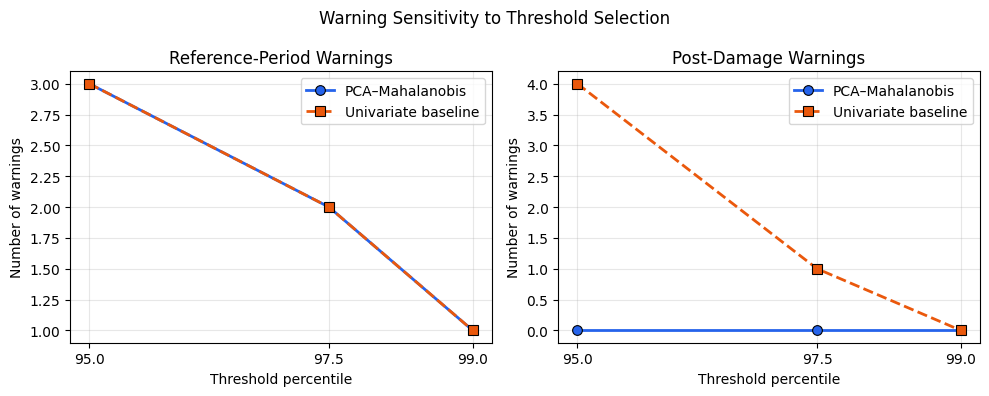

In [ ]:
# ◆ STEP 9 | THRESHOLD-SENSITIVITY PLOT

import matplotlib.pyplot as plt

style_map = {
    "PCA–Mahalanobis": {
        "color": "#2563EB",
        "linestyle": "-",
        "marker": "o",
        "zorder": 2,
    },
    "Univariate baseline": {
        "color": "#EA580C",
        "linestyle": "--",
        "marker": "s",
        "zorder": 4,
    },
}

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4),
    sharex=True,
)

for method_name, method_data in threshold_sensitivity.groupby("Method"):

    style = style_map[method_name]

    axes[0].plot(
        method_data["Percentile"],
        method_data["Reference warnings"],
        label=method_name,
        color=style["color"],
        linestyle=style["linestyle"],
        marker=style["marker"],
        linewidth=2,
        markersize=7,
        zorder=style["zorder"],
        markeredgecolor="black",
markeredgewidth=0.8,
    )

    axes[1].plot(
        method_data["Percentile"],
        method_data["Post-damage warnings"],
        label=method_name,
        color=style["color"],
        linestyle=style["linestyle"],
        marker=style["marker"],
        linewidth=2,
        markersize=7,
        zorder=style["zorder"],
        markeredgecolor="black",
markeredgewidth=0.8,
    )

axes[0].set_title("Reference-Period Warnings")
axes[1].set_title("Post-Damage Warnings")

for axis in axes:
    axis.set_xlabel("Threshold percentile")
    axis.set_xticks(threshold_percentiles)
    axis.set_ylabel("Number of warnings")
    axis.grid(alpha=0.3)
    axis.legend()

fig.suptitle("Warning Sensitivity to Threshold Selection")

plt.tight_layout()

fig.savefig(
    "threshold_sensitivity.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### Interpretation

At the 95th percentile, both methods generated 3 reference-period warnings. The univariate baseline also generated 4 post-damage warnings, while PCA–Mahalanobis generated none.

At the 97.5th percentile, both methods generated 2 reference-period warnings. The baseline generated 1 post-damage warning, while PCA–Mahalanobis generated none.

At the 99th percentile, both methods generated 1 reference-period warning and no post-damage warnings.

The plot shows that increasing the threshold reduces warnings, while the baseline is more sensitive at lower thresholds than PCA–Mahalanobis.

The directional diagnostic is not included in this plot because it is an exploratory, label-informed method with a separately defined score and threshold. It is evaluated separately and compared with the two reference-based methods in the final method comparison.

In [ ]:
# ◆ STEP 9 | FORMAL PERFORMANCE EVALUATION

damage_date = pd.Timestamp(
    "2023-03-09 23:45:25"
)

def evaluate_method(results):

    event_times = pd.to_datetime(
        results["Time"]
    )

    pre_damage_mask = (
        event_times < damage_date
    )

    damage_event_mask = (
        event_times == damage_date
    )

    post_damage_mask = (
        event_times > damage_date
    )

    reference_warnings = results.loc[
        pre_damage_mask,
        "Warning"
    ]

    damage_event_warnings = results.loc[
        damage_event_mask,
        "Warning"
    ]

    post_damage_warnings = results.loc[
        post_damage_mask,
        "Warning"
    ]

    post_warning_times = results.loc[
        post_damage_mask
        & results["Warning"],
        "Time"
    ]

    if len(post_warning_times) > 0:
        first_post_warning = post_warning_times.min()

        detection_delay = (
            pd.Timestamp(first_post_warning)
            - damage_date
        ).total_seconds() / 86400
    else:
        first_post_warning = pd.NaT
        detection_delay = np.nan

    return {
        "Reference-period warning rate": (
            reference_warnings.mean()
        ),
        "Reference-period warnings": int(
            reference_warnings.sum()
        ),
        "Damage-time warnings": int(
            damage_event_warnings.sum()
        ),
        "Post-damage warnings": int(
            post_damage_warnings.sum()
        ),
        "First post-damage warning": (
            first_post_warning
        ),
        "Detection delay (days)": (
            detection_delay
        ),
    }

evaluation_summary = pd.DataFrame({
    "PCA–Mahalanobis": evaluate_method(
        condition_results
    ),
    "Univariate baseline": evaluate_method(
        baseline_results
    ),
}).T

display(
    evaluation_summary.round(3)
)

,Reference-period warning rate,Reference-period warnings,Damage-time warnings,Post-damage warnings,First post-damage warning,Detection delay (days)
PCA–Mahalanobis,0.017544,1,0,0,NaT,NaN
Univariate baseline,0.017544,1,0,0,NaT,NaN


### Interpretation

Both PCA–Mahalanobis and the univariate baseline generated one warning among the 57 pre-damage reference events, corresponding to an empirical reference-period exceedance rate of approximately 1.75%. This should not be interpreted as an independently validated false-alarm probability.

Because only one verified damage event is available, these results describe warning behavior rather than validated damage-detection performance.

In [ ]:
# ◆ STEP 9 | INSPECT CONDITION SCORES AROUND THE DAMAGE DATE

inspection_window = condition_results[
    (
        condition_results["Time"]
        >= pd.Timestamp("2023-03-05")
    )
    & (
        condition_results["Time"]
        <= pd.Timestamp("2023-03-11")
    )
].copy()

inspection_window["Baseline_score"] = (
    baseline_results.loc[
        inspection_window.index,
        "Baseline_score",
    ].values
)

inspection_window["Baseline_warning"] = (
    baseline_results.loc[
        inspection_window.index,
        "Warning",
    ].values
)

display(
    inspection_window[
        [
            "Event",
            "Time",
            "Condition_indicator",
            "Warning",
            "Baseline_score",
            "Baseline_warning",
        ]
    ]
)

,Event,Time,Condition_indicator,Warning,Baseline_score,Baseline_warning
47,47,2023-03-05 05:52:22,7.277896,True,7.347371,True
48,48,2023-03-05 19:30:10,3.288382,False,2.284003,False
49,49,2023-03-05 23:37:24,2.754589,False,1.852168,False
50,50,2023-03-06 13:33:15,3.341471,False,1.958671,False
51,51,2023-03-06 17:53:36,2.264238,False,2.226164,False
52,52,2023-03-07 06:37:08,3.924117,False,2.701818,False
53,53,2023-03-08 06:25:19,4.183399,False,2.950327,False
54,54,2023-03-08 14:34:30,4.810367,False,3.929265,False
55,55,2023-03-09 13:03:18,2.233979,False,1.921544,False
56,56,2023-03-09 21:53:28,3.280648,False,2.419294,False


### Interpretation

Event 47 was flagged by both the PCA–Mahalanobis method and the univariate baseline on 5 March 2023 at 05:52:22, approximately 4.75 days before the documented damage event on 9 March 2023 at 23:45:25. Agreement between the two methods strengthens the interpretation that the event exhibited an unusual sensor response. However, with only one verified damage event, this cannot be confirmed as predictive damage detection.

In [ ]:
# ◆ STEP 9 | PRE-/POST-DAMAGE EFFECT SIZES

damage_date = pd.Timestamp("2023-03-09 23:45:25")

damage_sensor_features = [
    "ch_9_mean",
    "ch_9_std",
    "ch_9_range",
    "ch_10_mean",
    "ch_10_std",
    "ch_10_range",
]

sensor_comparison = model_features[
    ["Event", "Time"] + damage_sensor_features
].copy()

sensor_comparison["Time"] = pd.to_datetime(
    sensor_comparison["Time"]
)

sensor_comparison["Period"] = np.where(
    sensor_comparison["Time"] < damage_date,
    "Pre-damage",
    "Damage-period"
)

effect_records = []

for feature in damage_sensor_features:
    pre_values = sensor_comparison.loc[
        sensor_comparison["Period"] == "Pre-damage",
        feature
    ].dropna()

    post_values = sensor_comparison.loc[
        sensor_comparison["Period"] == "Damage-period",
        feature
    ].dropna()

    pooled_std = np.sqrt(
        (
            (len(pre_values) - 1) * pre_values.var()
            + (len(post_values) - 1) * post_values.var()
        )
        / (len(pre_values) + len(post_values) - 2)
    )

    standardized_effect = (
        (post_values.mean() - pre_values.mean()) / pooled_std
        if pooled_std > 0
        else np.nan
    )

    effect_records.append({
        "Feature": feature,
        "Pre-damage mean": pre_values.mean(),
        "Damage-period mean": post_values.mean(),
        "Mean difference": (
            post_values.mean() - pre_values.mean()
        ),
        "Standardized effect": standardized_effect,
    })

effect_summary = (
    pd.DataFrame(effect_records)
    .sort_values(
        "Standardized effect",
        key=lambda x: x.abs(),
        ascending=False
    )
)

display(effect_summary.round(4))

,Feature,Pre-damage mean,Damage-period mean,Mean difference,Standardized effect
5,ch_10_range,360.3260,326.0686,-34.2574,-3.0801
2,ch_9_range,534.8402,555.3043,20.4641,1.8610
4,ch_10_std,102.8817,85.5141,-17.3676,-1.0088
0,ch_9_mean,1047.0980,1104.0801,56.9821,0.8870
3,ch_10_mean,870.2693,850.2240,-20.0454,-0.5181
1,ch_9_std,172.4996,171.1269,-1.3727,-0.0484


### Interpretation

The largest standardized change occurs in `ch_10_range`, which decreases during the damage period with a standardized effect of −3.0801. In contrast, `ch_9_range` increases with a standardized effect of 1.8610. This opposite-direction response is consistent with the SG9–SG10 directional diagnostic.

Because the comparison periods are defined using the documented damage timestamp, this result is descriptive and label-informed rather than independent predictive validation.

### Damage-Related Feature Demonstration

The distributions of SG9 and SG10 range features are compared before and after the documented damage date. These features are used in the exploratory directional diagnostic.

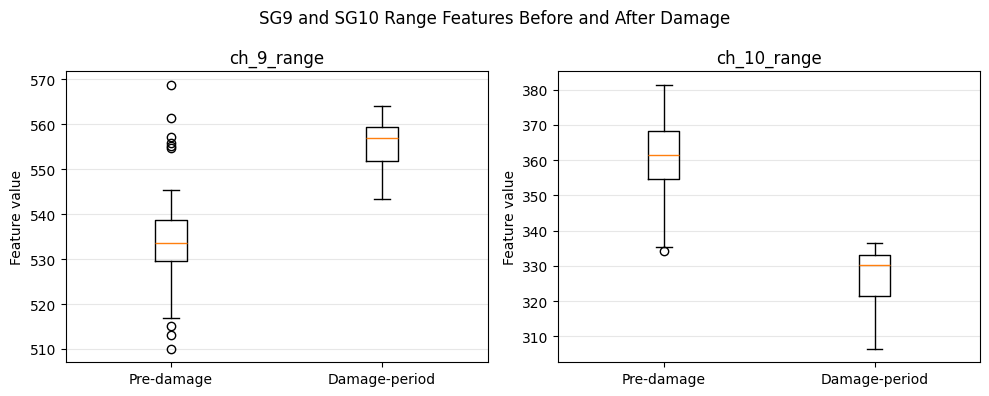

In [ ]:
# ◆ STEP 9 | DAMAGE-RELATED FEATURE COMPARISON PLOT

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1,
    2,
)
damage_plot_features = [
    "ch_9_range",
    "ch_10_range",
]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4),
)

for axis, feature in zip(
    axes,
    damage_plot_features,
):

    grouped_values = [
        sensor_comparison.loc[
            sensor_comparison["Period"]
            == "Pre-damage",
            feature,
        ].dropna(),

        sensor_comparison.loc[
            sensor_comparison["Period"]
            == "Damage-period",
            feature,
        ].dropna(),
    ]

    axis.boxplot(
        grouped_values,
        tick_labels=[
            "Pre-damage",
            "Damage-period",
        ],
    )

    axis.set_title(feature)
    axis.set_ylabel("Feature value")
    axis.grid(
        axis="y",
        alpha=0.3,
    )

fig.suptitle(
    "SG9 and SG10 Range Features Before and After Damage"
)

plt.tight_layout()
plt.show()

### Interpretation

The plot visualizes the SG9–SG10 feature changes used by the directional diagnostic. The changes are descriptive and label-informed because the documented damage date defines the comparison periods.

In [ ]:
# ◆ STEP 9 | INITIAL DETECTION PERFORMANCE

damage_date = pd.Timestamp("2023-03-09 23:45:25")

flagged_events = condition_results[
    condition_results["Warning"]
]

reference_warnings = condition_results[
    reference_mask
]["Warning"].sum()

first_warning_time = (
    flagged_events["Time"].min()
)

detection_lead_days = (
    damage_date - first_warning_time
).total_seconds() / 86400

performance_summary = pd.DataFrame({
    "Metric": [
        "Flagged events",
        "Reference-period warnings",
        "First warning time",
        "Detection lead time (days)",
    ],
    "Result": [
        len(flagged_events),
        int(reference_warnings),
        first_warning_time,
        round(detection_lead_days, 2),
    ],
})

display(performance_summary)


,Metric,Result
0,Flagged events,1
1,Reference-period warnings,1
2,First warning time,2023-03-05 05:52:22
3,Detection lead time (days),4.75


### Interpretation

The PCA–Mahalanobis model generated one reference-period warning at 2023-03-05 05:52:22, approximately 4.75 days before the documented damage timestamp.

This warning may represent an early abnormal response, but it cannot be classified as confirmed damage detection. Because it occurred within the pre-damage reference period, it is reported as a reference-period warning rather than as a validated damage prediction.

Further comparison with the sensor responses and alternative thresholds is required before drawing a final conclusion.

In [ ]:
# ◆ STEP 9 | METHOD COMPARISON

damage_date = pd.Timestamp(
    "2023-03-09 23:45:25"
)

def summarize_method(
    method_name,
    results,
):

    event_times = pd.to_datetime(
        results["Time"]
    )

    pre_damage_mask = (
        event_times < damage_date
    )

    damage_event_mask = (
        event_times == damage_date
    )

    post_damage_mask = (
        event_times > damage_date
    )

    reference_warning_count = int(
        results.loc[
            pre_damage_mask,
            "Warning"
        ].sum()
    )

    damage_event_warning_count = int(
        results.loc[
            damage_event_mask,
            "Warning"
        ].sum()
    )

    post_warning_count = int(
        results.loc[
            post_damage_mask,
            "Warning"
        ].sum()
    )

    post_warning_times = results.loc[
        post_damage_mask
        & results["Warning"],
        "Time"
    ]

    if len(post_warning_times) > 0:

        first_warning = post_warning_times.min()

        delay_days = (
            pd.Timestamp(first_warning)
            - damage_date
        ).total_seconds() / 86400

    else:

        first_warning = pd.NaT
        delay_days = np.nan

    return {
        "Method": method_name,
        "Reference warnings": (
            reference_warning_count
        ),
        "Damage-time warnings": (
            damage_event_warning_count
        ),
        "Post-damage warnings": (
            post_warning_count
        ),
        "First post-damage warning": (
            first_warning
        ),
        "Detection delay (days)": (
            delay_days
        ),
    }


method_comparison = pd.DataFrame([
    summarize_method(
        "PCA–Mahalanobis",
        condition_results,
    ),
    summarize_method(
        "Univariate baseline",
        baseline_results,
    ),
    summarize_method(
        "Directional diagnostic",
        directional_results,
    ),
])

display(
    method_comparison
)

,Method,Reference warnings,Damage-time warnings,Post-damage warnings,First post-damage warning,Detection delay (days)
0,PCA–Mahalanobis,1,0,0,NaT,NaN
1,Univariate baseline,1,0,0,NaT,NaN
2,Directional diagnostic,1,1,6,2023-03-10 08:34:30,0.367419


### Interpretation

The PCA–Mahalanobis and univariate baseline methods each generated one reference-period warning, no damage-time warning, and no post-damage warnings.

The directional diagnostic generated one pre-damage warning, one damage-time warning, and six post-damage warnings. Its first true post-damage warning occurred approximately 0.37 days after the documented damage timestamp.

Because the directional feature direction was selected using knowledge of the documented damage event, this result is exploratory and label-informed rather than unbiased predictive evidence.

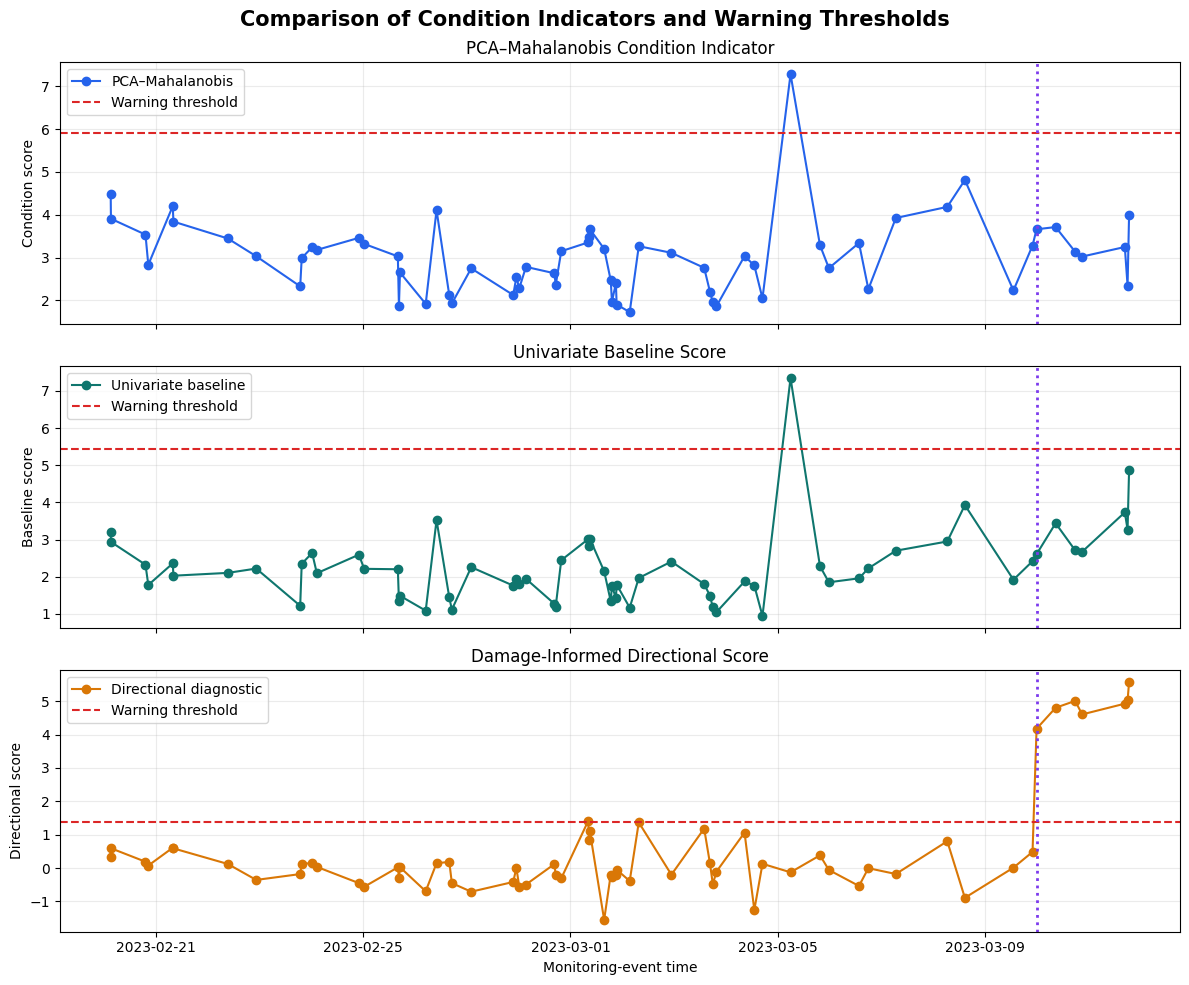

In [ ]:
# ◆ STEP 9 | CONDITION-SCORE VISUALIZATION

import matplotlib.pyplot as plt

damage_date = pd.Timestamp(
    "2023-03-09 23:45:25"
)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(12, 10),
    sharex=True,
)

# ◇ PCA–Mahalanobis score
axes[0].plot(
    condition_results["Time"],
    condition_results["Condition_indicator"],
    marker="o",
    color="#2563EB",
    label="PCA–Mahalanobis",
)

axes[0].axhline(
    warning_threshold,
    color="#DC2626",
    linestyle="--",
    label="Warning threshold",
)

axes[0].set_ylabel(
    "Condition score"
)

axes[0].set_title(
    "PCA–Mahalanobis Condition Indicator"
)

axes[0].legend()

# ◇ Univariate baseline score
axes[1].plot(
    baseline_results["Time"],
    baseline_results["Baseline_score"],
    marker="o",
    color="#0F766E",
    label="Univariate baseline",
)

axes[1].axhline(
    baseline_threshold,
    color="#DC2626",
    linestyle="--",
    label="Warning threshold",
)

axes[1].set_ylabel(
    "Baseline score"
)

axes[1].set_title(
    "Univariate Baseline Score"
)

axes[1].legend()

# ◇ Directional diagnostic score
axes[2].plot(
    directional_results["Time"],
    directional_results["Directional_score"],
    marker="o",
    color="#D97706",
    label="Directional diagnostic",
)

axes[2].axhline(
    directional_threshold,
    color="#DC2626",
    linestyle="--",
    label="Warning threshold",
)

axes[2].set_ylabel(
    "Directional score"
)

axes[2].set_title(
    "Damage-Informed Directional Score"
)

axes[2].legend()

# ◇ Documented damage timestamp
for axis in axes:

    axis.axvline(
        damage_date,
        color="#7C3AED",
        linestyle=":",
        linewidth=2,
        label="Documented damage time",
    )

    axis.grid(
        alpha=0.25
    )

axes[-1].set_xlabel(
    "Monitoring-event time"
)

fig.suptitle(
    "Comparison of Condition Indicators and Warning Thresholds",
    fontsize=15,
    fontweight="bold",
)

plt.tight_layout()

fig.savefig(
    "anomaly_scores.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### Interpretation

The PCA–Mahalanobis and univariate scores show isolated pre-damage exceedances but no sustained warning pattern after the documented damage timestamp.

The directional score reaches its threshold at the damage-time event and remains above the threshold for several subsequent events. This illustrates that the SG9–SG10 directional response captures a feature-specific change that is not represented by the two aggregate scores.

Because the directional score was developed using knowledge of the documented damage pattern, it is interpreted as an exploratory, label-informed diagnostic rather than unbiased predictive evidence.

### Experimental Analysis of the Primary Approach

The experiments show that PCA–Mahalanobis provides a compact and interpretable multivariate condition indicator. The 36 standardized features were reduced to 10 principal components, which retained 95.7% of the reference-period variation. The method also accounts for relationships among sensors rather than evaluating each feature independently.

The experiments also revealed important limitations. At the selected 99th-percentile threshold, the method generated one reference-period warning but no post-damage warnings. Its results changed when the reference period was shortened: shorter reference periods produced more post-damage warnings, but also more held-out pre-damage warnings. Adding environmental features changed the PCA representation but did not change the main warning outcome.

**These results are consistent with the literature**, which identifies multivariate reference-based methods as useful for correlated sensor data but sensitive to reference conditions, environmental variability, and threshold selection [1], [3], [4]. Because only one verified damage event is available, the results describe warning behavior rather than validated damage-detection performance [2].

A sensitivity analysis excluding the nine invalid-reading features produced the same warning outcome and the same threshold, indicating that the primary conclusion was not driven by the sensor-quality features.

### Comparative Analysis of the Alternative Approaches

The univariate baseline was simpler and easier to interpret because it used the largest absolute standardized feature value for each event. However, it did not model relationships among sensors. At the selected threshold, it produced the same outcome as PCA–Mahalanobis: one reference-period warning and no post-damage warnings.

The SG9–SG10 directional diagnostic provided feature-specific information that the two aggregate methods did not reveal. It generated one pre-damage warning, one warning at the documented damage timestamp, and six additional post-damage warnings. The first strictly post-damage warning occurred approximately 0.37 days after the documented damage timestamp. However, the diagnostic was exploratory and label-informed because its direction was selected using the known damage pattern. Accordingly, the directional diagnostic is reported as a post-damage feature-response demonstration, not as a predictive model-performance result.

Therefore, PCA–Mahalanobis provided the main multivariate framework, the univariate baseline provided a simple comparison, and the directional diagnostic provided exploratory engineering insight.

## 10. Conclusions, Engineering Interpretation, and Recommendations

### Summary of findings

The primary PCA–Mahalanobis model used 36 standardized features and retained 10 principal components, explaining 95.7% of the pre-damage reference variation. At the 99th-percentile threshold of 5.896, it generated one reference-period warning, no damage-time warning, and no post-damage warnings.

The univariate baseline produced the same outcome: one reference-period warning, no damage-time warning, and no post-damage warnings. Both methods flagged one event during the pre-damage reference period.

The directional SG9–SG10 diagnostic generated one pre-damage warning, one damage-time warning, and six post-damage warnings. The first true post-damage warning occurred approximately 0.37 days **after the documented damage** timestamp. This diagnostic was exploratory and label-informed.

| Analysis | Final result |
|---|---|
| PCA–Mahalanobis | 36 features, 10 PCs, 95.7% variance, threshold 5.896, 1 pre-damage warning, 0 damage-time warnings, and 0 post-damage warnings |
| Univariate baseline | 1 pre-damage warning, 0 damage-time warnings, and 0 post-damage warnings |
| Directional diagnostic | 1 pre-damage warning, 1 damage-time warning, and 6 post-damage warnings |
| First true directional post-damage warning | Approximately 0.37 days after the documented damage timestamp |
| Threshold sensitivity | At 95%: PCA 0 and baseline 4 post-damage warnings; at 97.5%: PCA 0 and baseline 1; at 99%: both 0 |
| Reference-period sensitivity | 70%: 6 held-out and 2 post-damage warnings; 85%: 1 held-out and 0 post-damage warnings; 100%: 0 held-out and 0 post-damage warnings |
| Feature-group sensitivity | Structural-only and structural-plus-environmental models both produced 1 reference-period warning and 0 post-damage warnings |
| Invalid-feature sensitivity | 27 features, 10 PCs, 95.8% variance, threshold 5.896, with the same warning outcome as the primary model |


### Engineering interpretation & Conclusions

The PCA–Mahalanobis and univariate methods did not identify a sustained post-damage warning pattern. In contrast, the directional diagnostic revealed a feature-specific SG9–SG10 response that was not detected by either aggregate method.

The methods can identify unusual sensor behavior that may help prioritize events for inspection. However, an anomaly warning does not by itself confirm structural damage because the PCA–Mahalanobis and univariate methods produced no post-damage warnings, while the directional result was exploratory and label-informed.

The **literature gap** was the limited evaluation of whether anomaly-detection methods can support inspection prioritization when only one verified damage event is available. **This project addresses that gap** by comparing a multivariate PCA–Mahalanobis indicator with a univariate baseline on a real bridge dataset and evaluating post-damage warnings, detection delay, threshold sensitivity, reference-period sensitivity, and feature-group sensitivity. The results show that the two reference-based methods identified unusual pre-damage behaviour but no true post-damage warnings under the selected configuration, while the label-informed directional diagnostic revealed a feature-specific post-damage response. Therefore, anomaly indicators are useful for prioritizing inspection review but should not be treated as independent confirmation of structural damage.

These findings **address the three project objectives** as follows:
1. **Inspection prioritization:** The monitoring data identified unusual events that can support inspection prioritization. Event 47 was flagged by both PCA–Mahalanobis and the univariate baseline, while the SG9–SG10 diagnostic revealed an additional feature-specific response. These warnings should support review, not be treated as confirmation of structural damage.

2. **Warning reliability:** The PCA–Mahalanobis and univariate methods generated no true post-damage warnings under the selected configuration. Their results were sensitive to the threshold and reference-period definition. The directional diagnostic produced post-damage warnings, but it was exploratory and label-informed.

3. **Engineering guidance:** The results support using PCA–Mahalanobis and the univariate baseline as conservative screening tools, reviewing jointly flagged events and contributing sensor features, and confirming warnings through inspection or independent engineering evidence.

### Engineering recommendations

For practical inspection support:

- Use the PCA–Mahalanobis and univariate methods as conservative screening indicators.
- Review events flagged by both methods, such as Event 47, using the event time and contributing sensor features.
- Use SG9–SG10 directional changes as supplementary, feature-level information when interpreting warnings.
- Avoid basing maintenance decisions on a single warning or on the directional diagnostic alone.
- Confirm warnings using physical inspection, additional sensor evidence, or independent engineering information before taking maintenance action.

### Limitations and future work

The analysis contains only one verified damage event, so the results describe warning behavior rather than validated predictive performance. Warning outcomes are also sensitive to the definition of the pre-damage reference period.

The directional diagnostic is label-informed, and the available monitoring duration and number of events are limited. Future work should use longer monitoring records with additional confirmed damage and normal-operation events before real-world deployment.

## 11. AI Use and Reflection

Generative AI, specifically ChatGPT, was used as a supporting tool for code drafting, debugging, plotting, and notebook organization. It also supported discussion of alternative analytical methods.

AI-generated suggestions were checked by executing the code, comparing outputs with the dataset documentation and course materials, and reviewing their engineering plausibility. Suggestions that produced inconsistent results or unsupported interpretations were revised or rejected.

For example, the initial anomaly analysis was revised after evaluation showed that the PCA–Mahalanobis and univariate baseline methods did not detect the post-damage events. The final interpretation therefore reports this limitation rather than claiming successful damage detection.

Also, during a later audit, an inconsistency was identified because the code used only the damage date and did not include the exact documented damage time. Consequently, events occurring earlier on 9 March were initially classified as post-damage. The timestamp was corrected to 2023-03-09 23:45:25, the affected cells were rerun, and the warning counts and detection delays were rechecked. This demonstrated the importance of checking date-time precision and boundary conditions in event-based analyses.

The study methodology was also checked against the seven-step machine-learning procedure described by Khamis (2019), which informed the sequence of the work. See: [Khamis (2019), *The 7-Step Procedure of Machine Learning*](https://medium.com/data-science/the-7-step-procedure-of-machine-learning-c15c922e7300).

## 12. Analysis Logic Summary

The following table summarizes the logic of the analysis and the reason for each major step.

| Step | Logic | Reason |
|---|---|---|
| Data collection | Retrieve and verify the public bridge-monitoring dataset | Ensure reproducibility and confirm the correct data source |
| Data-quality audit | Check channels, timestamps, missing values, duplicate records, and invalid readings | Confirm that the data are suitable for analysis |
| Feature engineering | Convert high-frequency measurements into event-level summary features | Make monitoring events comparable |
| PCA–Mahalanobis | Combine correlated standardized features into a multivariate anomaly score | Use the primary multisensor detection approach |
| Univariate baseline | Use the largest absolute standardized feature value for each event | Provide a simpler comparison method |
| Directional diagnostic | Combine SG9–SG10 feature changes into a directional score | Examine feature-specific damage-related behaviour |
| Threshold sensitivity | Test the 95th, 97.5th, and 99th percentiles | Assess the effect of threshold selection |
| Reference-period sensitivity | Refit the model using 70%, 85%, and 100% of the pre-damage events | Assess dependence on the definition of normal behaviour |
| Feature-group sensitivity | Compare structural-only with structural-plus-environmental features | Assess the influence of environmental information |
| Invalid-feature sensitivity | Remove invalid-reading features and repeat the analysis | Check whether sensor-quality variables drive the result |
| Method evaluation | Count pre-damage, damage-time, and post-damage warnings | Quantify warning behaviour |
| Detection delay | Calculate the time from the documented damage timestamp to the first true post-damage warning | Measure the response timing |
| Feature-level review | Identify the features contributing most strongly to a warning | Make the anomaly result interpretable |
| Engineering interpretation | Translate the results into inspection-support guidance | Connect the analysis to the maintenance problem |
| Limitations | State the effects of one verified damage event, limited monitoring duration, and label-informed analysis | Prevent unsupported conclusions |

The directional diagnostic is interpreted separately from the two reference-based methods because its feature direction was selected using knowledge of the documented damage pattern. It therefore provides exploratory feature-response evidence rather than unbiased predictive performance.

## 13. Dashboard Data Export

The preceding sections contain the complete analytical workflow and results. The following cell exports the validated event-level scores, warning decisions, and fixed thresholds used in the analysis to a CSV file for the accompanying Streamlit dashboard.

The dashboard uses the same thresholds as the notebook and paper. Its simulation controls modify the anomaly scenario only; they do not change the validated analytical results.

In [ ]:
# Export validated event-level results and fixed paper thresholds
# for the Streamlit dashboard

dashboard_data = pd.DataFrame({
    "Event": condition_results["Event"].to_numpy(),
    "Time": pd.to_datetime(condition_results["Time"]).to_numpy(),

    "PCA_Mahalanobis": condition_results[
        "Condition_indicator"
    ].to_numpy(),

    "PCA_Warning": condition_results[
        "Warning"
    ].to_numpy(),

    "Univariate_baseline": baseline_results[
        "Baseline_score"
    ].to_numpy(),

    "Baseline_Warning": baseline_results[
        "Warning"
    ].to_numpy(),

    # Fixed thresholds used in the validated notebook analysis
    "PCA_threshold": warning_threshold,
    "Baseline_threshold": baseline_threshold,
})

dashboard_data.to_csv(
    "dashboard_input.csv",
    index=False
)

print("Dashboard input file created:")
print("dashboard_input.csv")
print(dashboard_data.head())
print()
print(f"PCA threshold exported: {warning_threshold:.6f}")
print(f"Baseline threshold exported: {baseline_threshold:.6f}")

Dashboard input file created:
dashboard_input.csv
   Event                Time  PCA_Mahalanobis  PCA_Warning  \
0      0 2023-02-20 03:10:53         4.474752        False   
1      1 2023-02-20 03:17:23         3.906569        False   
2      2 2023-02-20 19:17:06         3.536151        False   
3      3 2023-02-20 20:35:06         2.832640        False   
4      4 2023-02-21 07:54:28         4.201190        False   

   Univariate_baseline  Baseline_Warning  PCA_threshold  Baseline_threshold  
0             3.202922             False       5.896079            5.433231  
1             2.938527             False       5.896079            5.433231  
2             2.325138             False       5.896079            5.433231  
3             1.779657             False       5.896079            5.433231  
4             2.360601             False       5.896079            5.433231  

PCA threshold exported: 5.896079
Baseline threshold exported: 5.433231


### Live dashboard

The exported results are used by the deployed dashboard:

[Open the Bridge Structural Health Monitoring Dashboard](https://bridge-shm-anomaly-detection.streamlit.app)